# Медицинская мультиагентная система по приоритизации пациентов

Автоматический ML-пайплайн для медицинских табличных данных. На вход поступает размеченный датасет, на выходе дает ранжированный список наблюдений, требующих приоритетного внимания, и HTML-отчёт с характеристикой данных, сравнением моделей и описанием выбранного решения

## Область применения

Система рассчитана на медицинские табличные данные, где нужно выделить пациентов с повышенным риском какого-то исхода (например, повторной госпитализации или осложнений)

Конкретная задача и целевая переменная определяются автоматически исходя из структуры входного датасета

Тестирование выполнено на датасете [Diabetes 130-US Hospitals (1999-2008)](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) UCI ML Repository (изначально содержит 101 766 записей, 51 признак, включая текстовое описание карточки пациента)

## Используемые LLM

В пайплайне используются три модели, подключенные через OpenRouter. Модели выбраны на основе актуальных бенчмарков (Artificial Analysis, LMArena, Vellum). Более тяжёлые модели (например, Claude Opus или Gemini Pro) здесь не используются, тк их сильные стороны (глубокий reasoning) не особо нужны, потому что в пайплайне в основном короткие и структурированные запросы, оптимальные по цене токенов


| Модель | OpenRouter ID | Параметры | Назначение |
|---|---|---|---|
| GPT-4o | `openai/gpt-4o` | T=0, max=800, top_p=0.9 | Аналитические шаги со структурированным JSON |
| Gemini 2.5 Flash Lite | `google/gemini-2.5-flash-lite` | T=0, max=500, top_p=0.85 | Короткие решения, выбор из фиксированного пула |
| Claude 3.5 Haiku | `anthropic/claude-3.5-haiku` | T=0.1, max=600, top_p=0.95 | Верификация решений, self-critique |

## Как устроен пайплайн

Пайплайн реализован через LangGraph и состоит из 10 шагов:
1. Инициализация долговременной памяти
2. Загрузка данных и инференс схемы
3. Разведочный анализ
4. Предобработка
5. Инжиниринг признаков
6. Обучение моделей
7. Выбор метрики и лучшего решения
8. Формирование приоритетного списка
9. Сохранение памяти
10. Генерация отчёта

Граф содержит три условных ветвления на ошибку, внутреннее ветвление по моделям с циклами и условную перезапись долговременной памяти при улучшении метрики

## Установка

In [27]:
!pip install -q langchain langchain-openai langgraph joblib pandas numpy scikit-learn seaborn matplotlib

## Импорты

In [28]:
import os
import io
import base64
import json
import datetime
import urllib.request
import zipfile
from typing import TypedDict, Optional

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score, log_loss, confusion_matrix,
)

from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, END

import joblib

In [29]:
%matplotlib inline
pd.options.mode.chained_assignment = None
pd.set_option('display.max_columns', 60)

В config/settings.env содержатся апи ключи. В папке приложен шаблон такого документа. 

Формат с обязательными полями:

OPENROUTER_API_KEY=sk-or-v1-

LANGCHAIN_API_KEY=

DATASET_URL=


DATASET_URL опциональный вариант передачи датасета. Если задан, датасет загружается по ссылке из облачного хранилища (прямой HTTPS, Google Drive, Dropbox). Если пуст, агент ищет файл в локальной папке input/.

In [30]:
CONFIG_PATH = "../config/settings.env"
ARTIFACTS_DIR = "../artifacts"
DATA_DIR = "../data"
INPUT_DIR = "../input"


def load_settings(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Settings file not found: {path}. "
            f"Copy settings.env.template to settings.env and fill in OPENROUTER_API_KEY."
        )
    result = {}
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            key, _, value = line.partition("=")
            result[key.strip()] = value.strip().strip('"').strip("'")
    return result


settings = load_settings(CONFIG_PATH)

if not settings.get("OPENROUTER_API_KEY"):
    raise ValueError(
        f"OPENROUTER_API_KEY is missing in {CONFIG_PATH}. "
        f"Get a key at https://openrouter.ai/keys."
    )

os.environ["OPENROUTER_API_KEY"] = settings["OPENROUTER_API_KEY"]
DATASET_URL = settings.get("DATASET_URL", "").strip()

if settings.get("LANGCHAIN_API_KEY"):
    os.environ["LANGCHAIN_API_KEY"] = settings["LANGCHAIN_API_KEY"]
    os.environ["LANGCHAIN_TRACING_V2"] = "true"
    os.environ["LANGCHAIN_PROJECT"] = "medical-prioritization"
    import logging
    class _LangSmithSizeFilter(logging.Filter):
        def filter(self, record):
            msg = record.getMessage()
            if "exceeds maximum allowed size" in msg or "Failed to send compressed multipart ingest" in msg:
                return False
            return True
    for logger_name in ("langsmith", "langsmith.client", "langchain_core", "langchain"):
        logging.getLogger(logger_name).addFilter(_LangSmithSizeFilter())
    print("LangSmith: tracing enabled, oversized-batch warnings filtered")
else:
    os.environ["LANGCHAIN_TRACING_V2"] = "false"

os.makedirs(ARTIFACTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(INPUT_DIR, exist_ok=True)

data_source = "URL" if DATASET_URL else "local input/ folder"
print(f"Settings loaded: OPENROUTER_API_KEY=set, tracing={os.environ.get('LANGCHAIN_TRACING_V2')}, "
      f"data_source={data_source}")

LangSmith: tracing enabled, oversized-batch warnings filtered
Settings loaded: OPENROUTER_API_KEY=set, tracing=true, data_source=local input/ folder


## LLM-клиенты

In [31]:
OPENROUTER_BASE_URL = "https://openrouter.ai/api/v1"
OPENROUTER_KEY = os.environ["OPENROUTER_API_KEY"]

gpt = ChatOpenAI(
    model="openai/gpt-4o",
    temperature=0,
    max_tokens=800,
    top_p=0.9,
    base_url=OPENROUTER_BASE_URL,
    api_key=OPENROUTER_KEY,
)

gemini = ChatOpenAI(
    model="google/gemini-2.5-flash-lite",
    temperature=0,
    max_tokens=500,
    top_p=0.85,
    base_url=OPENROUTER_BASE_URL,
    api_key=OPENROUTER_KEY,
)

claude = ChatOpenAI(
    model="anthropic/claude-3.5-haiku",
    temperature=0.1,
    max_tokens=600,
    top_p=0.95,
    base_url=OPENROUTER_BASE_URL,
    api_key=OPENROUTER_KEY,
)


def ask_gpt(prompt):
    return gpt.invoke(prompt).content


def ask_gemini(prompt):
    return gemini.invoke(prompt).content


def ask_claude(prompt):
    return claude.invoke(prompt).content


def safe_json(raw):
    text = raw.strip().replace("```json", "").replace("```", "").strip()
    try:
        return json.loads(text)
    except Exception:
        return {}


from pydantic import BaseModel, Field
from typing import List as _List, Optional as _Optional, Dict as _Dict, Any as _Any
from langchain_core.output_parsers import PydanticOutputParser
def parse_with_fallback(raw_text, schema_cls, llm_for_fix=None):
    """Пытается строго распарсить через Pydantic. Если не получилось,
    при наличии llm_for_fix просит LLM исправить JSON. Финальный фолбэк - safe_json."""
    parser = PydanticOutputParser(pydantic_object=schema_cls)
    try:
        return parser.parse(raw_text).model_dump()
    except Exception:
        pass

    if llm_for_fix is not None:
        try:
            from langchain.output_parsers import OutputFixingParser
            fixing = OutputFixingParser.from_llm(parser=parser, llm=llm_for_fix)
            return fixing.parse(raw_text).model_dump()
        except Exception:
            pass

    fallback = safe_json(raw_text) or {}
    try:
        return schema_cls(**fallback).model_dump()
    except Exception:
        return fallback



class IngestTopicResponse(BaseModel):
    dataset_topic_guess: str = Field(description="Best-effort topic of the dataset")
    topic_confidence: str = Field(description="low | medium | high")


class IngestTargetResponse(BaseModel):
    dataset_topic_guess: _Optional[str] = None
    topic_confidence: _Optional[str] = None
    target_col: str = Field(description="Name of the target column")
    task_type: str = Field(description="binary or multiclass")
    cols_to_drop: _List[str] = Field(default_factory=list, description="Advisory drop list")
    reasoning: _Optional[str] = ""


class ExploreResponse(BaseModel):
    key_findings: str
    high_missing_cols: _List[str] = Field(default_factory=list)
    has_imbalance: bool = False
    recommend_undersample: bool = False
    suspected_outlier_cols: _List[str] = Field(default_factory=list)


class DropItem(BaseModel):
    column: str
    reason: _Optional[str] = ""


class FillOverride(BaseModel):
    column: str
    method: str
    value: _Optional[_Any] = None


class FillStrategy(BaseModel):
    numeric_default: str = "median"
    categorical_default: str = "mode"
    overrides: _List[FillOverride] = Field(default_factory=list)


class SelectColumnsResponse(BaseModel):
    drop: _List[DropItem] = Field(default_factory=list)
    fill_strategy: FillStrategy = Field(default_factory=FillStrategy)
    reasoning: _Optional[str] = ""


class TextFeatureSpec(BaseModel):
    name: str
    type: str
    description: _Optional[str] = ""
    terms: _Optional[_List[str]] = None
    pattern: _Optional[str] = None


class AnalyzeTextResponse(BaseModel):
    text_column: _Optional[str] = None
    features: _List[TextFeatureSpec] = Field(default_factory=list)
    reasoning: _Optional[str] = ""


class ReviewResponse(BaseModel):
    verdict: str = "approve"
    concerns: _List[str] = Field(default_factory=list)
    drop_overrides: _Optional[_Dict[str, _List[str]]] = None
    fill_overrides: _List[FillOverride] = Field(default_factory=list)
    text_features_overrides: _Optional[_Dict[str, _List[str]]] = None
    reasoning: _Optional[str] = ""


def parse_with_fallback(raw_text, schema_cls, llm_for_fix=None):
    """Строгий парсинг через Pydantic с фолбэком на LLM-фиксер и safe_json."""
    parser = PydanticOutputParser(pydantic_object=schema_cls)
    try:
        return parser.parse(raw_text).model_dump()
    except Exception:
        pass
    if llm_for_fix is not None:
        try:
            return OutputFixingParser.from_llm(parser=parser, llm=llm_for_fix).parse(raw_text).model_dump()
        except Exception:
            pass
    fallback = safe_json(raw_text) or {}
    try:
        return schema_cls(**fallback).model_dump()
    except Exception:
        return fallback


from langchain_core.tools import tool as _lc_tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage


def run_agent_loop(llm_with_tools, tools_map, system_prompt, user_prompt,
                   max_iterations=5, max_total_calls=10, tool_log=None):
    """Цикл агента с tool calling. Возвращает финальный текстовый ответ."""
    if tool_log is None:
        tool_log = []
    messages = [SystemMessage(content=system_prompt), HumanMessage(content=user_prompt)]
    total_calls = 0

    for iteration in range(max_iterations):
        try:
            response = llm_with_tools.invoke(messages)
        except Exception as e:
            print(f"  [agent] llm invoke failed: {type(e).__name__}: {e}")
            return None
        messages.append(response)
        tool_calls = getattr(response, "tool_calls", None) or []
        if not tool_calls:
            return getattr(response, "content", None) or str(response)

        for tc in tool_calls:
            tool_id = tc.get("id", f"call_{total_calls}")
            if total_calls >= max_total_calls:
                messages.append(ToolMessage(
                    content="ERROR: tool call quota exceeded. Give the final JSON now.",
                    tool_call_id=tool_id))
                continue
            total_calls += 1
            try:
                result = str(tools_map[tc["name"]].invoke(tc.get("args", {})))[:600]
            except Exception as e:
                result = f"ERROR: {type(e).__name__}: {e}"
            tool_log.append({"iteration": iteration + 1, "name": tc["name"],
                             "args": tc.get("args", {}), "result_preview": result[:200]})
            print(f"  [agent it.{iteration+1}] {tc['name']}({tc.get('args', {})}) -> {result[:80]}")
            messages.append(ToolMessage(content=result, tool_call_id=tool_id))

        if total_calls >= max_total_calls:
            try:
                return llm_with_tools.invoke(messages).content
            except Exception:
                return None

    return getattr(messages[-1], "content", None)


def make_select_columns_tools(df, target):
    @_lc_tool
    def get_column_distribution(column_name: str) -> str:
        if column_name not in df.columns:
            return f"column '{column_name}' not in dataframe"
        s = df[column_name]
        if pd.api.types.is_numeric_dtype(s):
            d = s.describe()
            return (f"numeric: min={d['min']:.2f}, max={d['max']:.2f}, "
                    f"mean={d['mean']:.2f}, median={d['50%']:.2f}, std={d['std']:.2f}, "
                    f"missing={s.isnull().sum()}")
        vc = s.value_counts(normalize=True, dropna=False).head(10)
        return f"top-10 categorical values (share): {vc.round(3).to_dict()}"

    @_lc_tool
    def get_correlation_with_target(column_name: str) -> str:
        if column_name not in df.columns:
            return f"column '{column_name}' not in dataframe"
        s, y = df[column_name], df[target]
        try:
            if pd.api.types.is_numeric_dtype(s) and pd.api.types.is_numeric_dtype(y):
                return f"pearson_corr_with_{target} = {s.corr(y):.3f}"
            ct = pd.crosstab(s.fillna("__nan__").astype(str), y)
            from scipy.stats import chi2_contingency
            chi2, _, _, _ = chi2_contingency(ct)
            n, r, k = ct.values.sum(), *ct.shape
            denom = n * (min(r, k) - 1) if min(r, k) > 1 else 1
            cramers_v = (chi2 / denom) ** 0.5 if denom else 0.0
            return f"cramers_v_with_{target} = {cramers_v:.3f}"
        except Exception as e:
            return f"error: {type(e).__name__}: {e}"

    @_lc_tool
    def compare_columns(col_a: str, col_b: str) -> str:
        if col_a not in df.columns or col_b not in df.columns:
            return f"one of columns not found"
        a = df[col_a].astype(str).fillna("")
        b = df[col_b].astype(str).fillna("")
        agreement = float((a == b).mean())
        return (f"agreement_rate = {agreement:.3f} "
                f"({'likely duplicates' if agreement > 0.85 else 'distinct columns'})")

    return [get_column_distribution, get_correlation_with_target, compare_columns]


def make_analyze_text_tools(df, text_col_candidates):
    @_lc_tool
    def sample_random_notes(column_name: str, n: int = 5) -> str:
        if column_name not in df.columns:
            return f"column '{column_name}' not found"
        try:
            n = max(1, min(int(n), 10))
        except Exception:
            n = 5
        samples = df[column_name].dropna().astype(str).sample(n=min(n, len(df)), random_state=69).tolist()
        return "\n---\n".join(s[:300] for s in samples)

    @_lc_tool
    def count_term_in_notes(column_name: str, term: str) -> str:
        if column_name not in df.columns:
            return f"column '{column_name}' not found"
        s = df[column_name].astype(str).str.lower()
        cnt = int(s.str.contains(str(term).lower(), regex=False, na=False).sum())
        total = len(s)
        return f"term '{term}' appears in {cnt} of {total} notes ({100*cnt/total:.1f}%)"

    @_lc_tool
    def find_pattern_matches(column_name: str, pattern: str) -> str:
        if column_name not in df.columns:
            return f"column '{column_name}' not found"
        try:
            rx = re.compile(pattern)
        except re.error as e:
            return f"invalid regex: {e}"
        matches_per_row = df[column_name].astype(str).apply(lambda t: rx.findall(t))
        total_matches = int(matches_per_row.apply(len).sum())
        examples = []
        for m_list in matches_per_row.head(200):
            for m in m_list:
                if isinstance(m, tuple):
                    m = " ".join(str(x) for x in m)
                examples.append(str(m))
                if len(examples) >= 3:
                    break
            if len(examples) >= 3:
                break
        return f"total_matches={total_matches}, examples={examples[:3]}"

    return [sample_random_notes, count_term_in_notes, find_pattern_matches]


def _make_universal_tools(df, target):
    @_lc_tool
    def get_dataset_summary() -> str:
        n_rows, n_cols = df.shape
        target_balance = df[target].value_counts(normalize=True).round(3).to_dict()
        n_num = sum(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns if c != target)
        n_cat = (n_cols - 1) - n_num
        corrs = []
        for c in df.columns:
            if c == target:
                continue
            try:
                if pd.api.types.is_numeric_dtype(df[c]) and pd.api.types.is_numeric_dtype(df[target]):
                    cc = abs(df[c].corr(df[target]))
                else:
                    ct = pd.crosstab(df[c].fillna("__nan__").astype(str), df[target])
                    from scipy.stats import chi2_contingency
                    chi2, _, _, _ = chi2_contingency(ct)
                    n, r, k = ct.values.sum(), *ct.shape
                    denom = n * (min(r, k) - 1) if min(r, k) > 1 else 1
                    cc = (chi2 / denom) ** 0.5 if denom else 0.0
                if not (cc != cc):
                    corrs.append((c, float(cc)))
            except Exception:
                pass
        corrs.sort(key=lambda x: -x[1])
        top5 = [(c, round(v, 3)) for c, v in corrs[:5]]
        return (f"shape={n_rows}x{n_cols}, target_balance={target_balance}, "
                f"numeric_cols={n_num}, categorical_cols={n_cat}, "
                f"top5_corr_with_target={top5}")

    @_lc_tool
    def get_missingness_pattern(columns: str) -> str:
        cols = [c.strip() for c in str(columns).split(",") if c.strip() in df.columns]
        if not cols:
            return "no valid columns provided"
        sub = df[cols]
        missing_count = sub.isnull().sum(axis=1)
        n = len(sub)
        all_filled = int((missing_count == 0).sum())
        all_missing = int((missing_count == len(cols)).sum())
        partial = n - all_filled - all_missing
        return (f"of {n} rows: all filled = {all_filled} ({100*all_filled/n:.1f}%), "
                f"all missing = {all_missing} ({100*all_missing/n:.1f}%), "
                f"partial = {partial} ({100*partial/n:.1f}%)")

    @_lc_tool
    def check_feature_uniqueness(column_name: str) -> str:
        if column_name not in df.columns:
            return f"column not found"
        s = df[column_name]
        n_unique = int(s.nunique(dropna=False))
        n = len(s)
        ratio = n_unique / n if n else 0
        top3 = s.value_counts(dropna=False).head(3).to_dict()
        return (f"nunique={n_unique}, n_rows={n}, ratio={ratio:.3f}, "
                f"is_id_like={ratio > 0.5}, top3={top3}")

    return [get_dataset_summary, get_missingness_pattern, check_feature_uniqueness]


def make_engineer_features_tools(df, target):
    base_tools = make_select_columns_tools(df, target)[1:]

    @_lc_tool
    def test_interaction_strength(col_a: str, col_b: str, operation: str = "multiply") -> str:
        if col_a not in df.columns or col_b not in df.columns:
            return "one of columns not found"
        if not (pd.api.types.is_numeric_dtype(df[col_a]) and pd.api.types.is_numeric_dtype(df[col_b])):
            return "both columns must be numeric"
        try:
            a = df[col_a].astype(float)
            b = df[col_b].astype(float)
            ops = {"multiply": a * b, "divide": a / b.replace(0, 1e-9),
                   "sum": a + b, "subtract": a - b}
            if operation not in ops:
                return f"unknown operation '{operation}', use multiply|divide|sum|subtract"
            derived = ops[operation]
            y = df[target]
            if pd.api.types.is_numeric_dtype(y):
                base_a, base_b = abs(a.corr(y)), abs(b.corr(y))
                derived_corr = abs(derived.corr(y))
            else:
                from scipy.stats import f_oneway
                def _eta(x):
                    groups = [x[y == cls].dropna() for cls in y.unique() if (y == cls).sum() > 1]
                    return abs(f_oneway(*groups).statistic) ** 0.5 / 100 if len(groups) > 1 else 0
                base_a, base_b, derived_corr = _eta(a), _eta(b), _eta(derived)
            improvement = derived_corr - max(base_a, base_b)
            verdict = "USEFUL" if improvement > 0.01 else "NOT USEFUL"
            return (f"corr({col_a}={base_a:.3f}, {col_b}={base_b:.3f}, derived={derived_corr:.3f}), "
                    f"improvement={improvement:+.3f}, verdict={verdict}")
        except Exception as e:
            return f"error: {type(e).__name__}: {e}"

    return base_tools + [test_interaction_strength]


def make_review_decisions_tools(df, target):
    return make_select_columns_tools(df, target) + _make_universal_tools(df, target)


class EDAPlotSpec(BaseModel):
    type: str = Field(description="one of: target_distribution, correlation_heatmap, histogram_by_target, boxplot_by_target, stacked_bar_categorical, missingness_overview")
    column: _Optional[str] = None
    columns: _Optional[_List[str]] = None
    title: _Optional[str] = ""


class EDAPlotsResponse(BaseModel):
    plots: _List[EDAPlotSpec] = Field(default_factory=list)
    reasoning: _Optional[str] = ""


Перед запуском выполняются две предварительные проверки:

1. **Валидация API-ключа OpenRouter.** Запрос к GET /api/v1/key`возвращает статус ключа: активен, оставшиеся кредиты, дневные и месячные лимиты. Если ключ отозван или кредиты исчерпаны — пайплайн не запускается, чтобы не тратить время на полный прогон с гарантированной ошибкой.

2. **Проверка доступности моделей.** Запрос к GET /api/v1/models возвращает полный список активных моделей OpenRouter. Каждый из трёх выбранных идентификаторов (openai/gpt-4o, google/gemini-2.5-flash-lite, anthropic/claude-3.5-haiku) проверяется на присутствие в списке. Если модель исчезла (снята провайдером, переименована), LLM-арбитр получает список живых моделей того же класса и выбирает замену. Новый идентификатор подставляется в соответствующий ChatOpenAI-клиент прозрачно для остальных узлов графа.

Оба шага выполняются до построения графа. При неустранимых проблемах выбрасывается исключение с понятным сообщением о том, что именно пошло не так

In [32]:
import urllib.request
import urllib.error


def check_openrouter_key(api_key):
    req = urllib.request.Request(
        f"{OPENROUTER_BASE_URL}/key",
        headers={"Authorization": f"Bearer {api_key}"},
    )
    try:
        with urllib.request.urlopen(req, timeout=10) as resp:
            data = json.loads(resp.read().decode("utf-8"))
    except urllib.error.HTTPError as e:
        body = e.read().decode("utf-8", errors="ignore")
        raise RuntimeError(f"OpenRouter key check failed ({e.code}): {body}")
    except urllib.error.URLError as e:
        raise RuntimeError(f"OpenRouter unreachable: {e}")

    info = data.get("data", data)
    limit = info.get("limit")
    usage = info.get("usage", 0)
    is_free_tier = info.get("is_free_tier", False)

    if limit is not None and usage is not None and usage >= limit:
        raise RuntimeError(
            f"OpenRouter key exhausted: usage={usage} >= limit={limit}. "
            f"Top up balance at https://openrouter.ai/credits"
        )

    return {
        "valid": True,
        "usage": usage,
        "limit": limit,
        "is_free_tier": is_free_tier,
        "label": info.get("label", ""),
    }


def list_openrouter_models():
    req = urllib.request.Request(f"{OPENROUTER_BASE_URL}/models")
    try:
        with urllib.request.urlopen(req, timeout=15) as resp:
            payload = json.loads(resp.read().decode("utf-8"))
    except Exception as e:
        raise RuntimeError(f"Could not fetch OpenRouter models list: {e}")
    items = payload.get("data", [])
    return {item["id"]: item for item in items if "id" in item}


ROLE_CANDIDATES = {
    "analytical": [
        "openai/gpt-4o",
        "openai/gpt-4o-mini",
        "anthropic/claude-3.5-sonnet",
        "anthropic/claude-sonnet-4.5",
    ],
    "fast_json": [
        "google/gemini-2.5-flash-lite",
        "google/gemini-2.5-flash",
        "google/gemini-2.0-flash-001",
        "openai/gpt-4o-mini",
    ],
    "verifier": [
        "anthropic/claude-3.5-haiku",
        "anthropic/claude-haiku-4.5",
        "anthropic/claude-3.5-sonnet",
        "openai/gpt-4o-mini",
    ],
}


def pick_replacement_model(role, broken_model_id, available_models):
    candidates = ROLE_CANDIDATES.get(role, [])
    live = [m for m in candidates if m in available_models and m != broken_model_id]
    if not live:
        live = [m for m in available_models if m != broken_model_id][:20]
        if not live:
            raise RuntimeError(f"No replacement candidates for role {role}")

    prompt = (
        "You are selecting a replacement LLM model. The previously chosen model is no longer available.\n\n"
        f"Role: {role}\n"
        f"Broken model: {broken_model_id}\n"
        f"Candidate replacements (in priority order):\n"
        + "\n".join(f"- {m}" for m in live[:15]) + "\n\n"
        "Pick exactly one candidate that best fits the role. Consider:\n"
        "- analytical: structured JSON, long numbered instructions\n"
        "- fast_json: short decisions, low cost, high throughput\n"
        "- verifier: critique and review, medium temperature tolerance\n\n"
        "Return strictly JSON: {\"chosen_model\": \"provider/model-id\", \"reasoning\": \"...\"}"
    )

    try:
        raw = ask_claude(prompt) if role != "verifier" else ask_gemini(prompt)
        result = safe_json(raw)
        choice = result.get("chosen_model") if result else None
        if choice in live:
            return choice, result.get("reasoning", "")
    except Exception:
        pass

    return live[0], "first live candidate (LLM arbitration unavailable)"


def preflight(gpt_model, gemini_model, claude_model):
    key_info = check_openrouter_key(OPENROUTER_KEY)
    print(f"  API key: valid (usage={key_info['usage']}, limit={key_info['limit']})")

    available = list_openrouter_models()
    print(f"  OpenRouter models catalog: {len(available)} active models")

    assignments = {
        "analytical": ("gpt", gpt_model),
        "fast_json": ("gemini", gemini_model),
        "verifier": ("claude", claude_model),
    }

    resolved = {}
    replacements = []
    for role, (var_name, model_id) in assignments.items():
        if model_id in available:
            resolved[var_name] = model_id
            print(f"  {var_name}: {model_id} -> OK")
        else:
            replacement, reasoning = pick_replacement_model(role, model_id, available)
            resolved[var_name] = replacement
            replacements.append({
                "role": role,
                "original": model_id,
                "replacement": replacement,
                "reasoning": reasoning,
            })
            print(f"  {var_name}: {model_id} -> UNAVAILABLE, replaced with {replacement}")
            print(f"    reasoning: {reasoning}")

    return resolved, replacements, key_info


resolved_models, preflight_replacements, preflight_key_info = preflight(
    "openai/gpt-4o",
    "google/gemini-2.5-flash-lite",
    "anthropic/claude-3.5-haiku",
)

if resolved_models["gpt"] != "openai/gpt-4o":
    gpt = ChatOpenAI(
        model=resolved_models["gpt"], temperature=0, max_tokens=800, top_p=0.9,
        base_url=OPENROUTER_BASE_URL, api_key=OPENROUTER_KEY,
    )
if resolved_models["gemini"] != "google/gemini-2.5-flash-lite":
    gemini = ChatOpenAI(
        model=resolved_models["gemini"], temperature=0, max_tokens=500, top_p=0.85,
        base_url=OPENROUTER_BASE_URL, api_key=OPENROUTER_KEY,
    )
if resolved_models["claude"] != "anthropic/claude-3.5-haiku":
    claude = ChatOpenAI(
        model=resolved_models["claude"], temperature=0.1, max_tokens=600, top_p=0.95,
        base_url=OPENROUTER_BASE_URL, api_key=OPENROUTER_KEY,
    )

print(f"\nPreflight complete. {len(preflight_replacements)} replacement(s) applied.")

  API key: valid (usage=0.6367011, limit=None)
  OpenRouter models catalog: 367 active models
  gpt: openai/gpt-4o -> OK
  gemini: google/gemini-2.5-flash-lite -> OK
  claude: anthropic/claude-3.5-haiku -> OK

Preflight complete. 0 replacement(s) applied.


## Память

Кратковременная память реализована в TypedDict State, передаётся между узлами графа

Долговременная память через файлы в artifacts/. При каждом запуске читается предыдущий лучший результат, новая метрика перезаписывает файл только при улучшении

In [33]:
class State(TypedDict):
    data_path: Optional[str]
    dataset_name: Optional[str]
    dataset_topic: Optional[str]
    topic_confidence: Optional[str]
    _df_json: Optional[str]
    _raw_notes: Optional[list]
    _text_col_name: Optional[str]
    _text_feature_specs: list
    _drop_columns: list
    _drop_reasons: dict
    _fill_strategy: dict
    _llm_suggested_drop_ingest: list
    _review_verdict: Optional[str]
    _review_concerns: list
    _review_actions: list
    _review_reasoning: Optional[str]
    _feature_importance: list
    _threshold_info: Optional[dict]
    _select_columns_tool_log: list
    _analyze_text_tool_log: list
    _review_tool_log: list
    _engineer_features_tool_log: list
    _eda_plot_specs: list
    target_col: Optional[str]
    task_type: Optional[str]
    num_cols: list
    cat_cols: list
    text_cols: list
    drop_cols: list
    _eda_report: Optional[str]
    _balance_report: Optional[str]
    prep_actions: list
    new_features: list
    models_trained: dict
    metrics: dict
    all_metrics: dict
    metric_strategy: Optional[str]
    primary_metric: Optional[str]
    secondary_metric: Optional[str]
    positive_label: Optional[int]
    best_model_name: Optional[str]
    best_score: Optional[float]
    best_metric: Optional[str]
    prev_best_score: Optional[float]
    priority_csv: Optional[str]
    html_report: Optional[str]
    llm_decisions: list
    retries: int
    _training_errors: list
    _X_te_json: Optional[str]
    _y_te_json: Optional[str]
    _target_class_names: list
    _apply_undersample: bool
    _balance_strategy: Optional[str]
    error: Optional[str]


def df_to_json(df):
    return df.to_json(orient="split")


def json_to_df(s):
    return pd.read_json(io.StringIO(s), orient="split")

## Инициализация памяти

Читает artifacts/best_metrics.json и если он существует, обнуляет поля текущей сессии.

In [34]:
def load_memory(state: State) -> State:
    prev_score = None
    prev_model = None
    prev_metric = None
    n_previous_runs = 0

    best_path = f"{ARTIFACTS_DIR}/best_metrics.json"
    if os.path.exists(best_path):
        with open(best_path) as f:
            prev = json.load(f)
        prev_score = prev.get("best_score")
        prev_model = prev.get("best_model")
        prev_metric = prev.get("best_metric")

    log_path = f"{ARTIFACTS_DIR}/run_log.json"
    if os.path.exists(log_path):
        with open(log_path) as f:
            n_previous_runs = len(json.load(f).get("runs", []))

    if prev_score is not None:
        print(f"[memory] Found {n_previous_runs} previous run(s). "
              f"Best so far: {prev_model} with {prev_metric}={prev_score}")
    else:
        print(f"[memory] No previous runs found. Starting fresh.")

    state["prev_best_score"] = prev_score
    state["llm_decisions"] = []
    state["models_trained"] = {}
    state["metrics"] = {}
    state["all_metrics"] = {}
    state["prep_actions"] = []
    state["new_features"] = []
    state["drop_cols"] = []
    state["retries"] = 0
    state["error"] = None
    state["priority_csv"] = None
    state["html_report"] = None
    return state

## Загрузка данных

Источник определяется автоматически по содержимому config/settings.env:

 Если в конфигурации задан DATASET_URL, агент скачивает файл по ссылке. Поддерживаются прямые HTTPS-ссылки, Google Drive (обычные share-URL автоматически преобразуются в direct download), Dropbox (в URL подставляется флаг dl=1). Скачанный файл кэшируется в data/.

Папка input/. Если DATASET_URL пуст, агент сканирует input/ и берёт первый найденный файл. ZIP-архивы распаковываются, внутри извлекается первый CSV

Файл приводится к pandas DataFrame. Значения пропусков, пустые строки нормализуются в `NaN`

Колонки классифицируются на три группы:
- **Числовые** — численные dtypes pandas
- **Категориальные** — object/string колонки с количеством уникальных значений менее 50, или с короткими значениями
- **Текстовые** — object/string колонки, у которых среднее количество символов в значении превышает 40, и более половины значений содержат пробелы (признак неструктурированного текста)

Если обнаружена текстовая колонка, её исходное содержимое сохраняется для последующего извлечения признаков (длина, маркеры риска)

LLM определяет предметную тему датасета, выбирает целевую переменную и список колонок, подлежащих исключению (идентификаторы, константы, поля с риском утечки таргета)

In [35]:
def _normalize_gdrive_url(url):
    if "drive.google.com" not in url:
        return url
    import re
    match = re.search(r"/d/([a-zA-Z0-9_-]+)", url)
    if match:
        file_id = match.group(1)
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    match = re.search(r"[?&]id=([a-zA-Z0-9_-]+)", url)
    if match:
        file_id = match.group(1)
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    return url


def _normalize_dropbox_url(url):
    if "dropbox.com" not in url:
        return url
    if "dl=1" in url:
        return url
    if "dl=0" in url:
        return url.replace("dl=0", "dl=1")
    sep = "&" if "?" in url else "?"
    return f"{url}{sep}dl=1"


def _extract_archive(archive_path, dest_dir):
    with zipfile.ZipFile(archive_path, "r") as z:
        csvs = [n for n in z.namelist() if n.lower().endswith(".csv")]
        if not csvs:
            raise FileNotFoundError("No CSV file found inside archive")
        target = csvs[0]
        z.extract(target, path=dest_dir)
        extracted_path = os.path.join(dest_dir, target)
        final_path = os.path.join(dest_dir, os.path.basename(target))
        if extracted_path != final_path:
            os.replace(extracted_path, final_path)
        return final_path


def fetch_from_url(url, cache_dir):
    os.makedirs(cache_dir, exist_ok=True)
    normalized = _normalize_gdrive_url(url)
    normalized = _normalize_dropbox_url(normalized)

    filename = os.path.basename(normalized.split("?")[0]) or "dataset_download"
    if not any(filename.lower().endswith(ext) for ext in [".csv", ".zip", ".tsv", ".xlsx"]):
        filename = filename + ".download"
    local_path = os.path.join(cache_dir, filename)

    if not os.path.exists(local_path):
        urllib.request.urlretrieve(normalized, local_path)

    if local_path.lower().endswith(".zip"):
        return _extract_archive(local_path, cache_dir)
    return local_path


def fetch_from_input_folder(input_dir, cache_dir):
    if not os.path.exists(input_dir):
        return None
    supported = [".csv", ".zip", ".tsv", ".xlsx"]
    candidates = []
    for name in os.listdir(input_dir):
        path = os.path.join(input_dir, name)
        if os.path.isfile(path) and any(name.lower().endswith(ext) for ext in supported):
            candidates.append(path)
    if not candidates:
        return None
    candidates.sort(key=os.path.getmtime, reverse=True)
    chosen = candidates[0]

    if chosen.lower().endswith(".zip"):
        return _extract_archive(chosen, cache_dir)
    return chosen


def resolve_dataset():
    if DATASET_URL:
        return fetch_from_url(DATASET_URL, DATA_DIR), "url"
    local = fetch_from_input_folder(INPUT_DIR, DATA_DIR)
    if local:
        return local, "input_folder"
    raise FileNotFoundError(
        f"No dataset source available. Either set DATASET_URL in {CONFIG_PATH} "
        f"or place a .csv/.zip/.tsv/.xlsx file into {INPUT_DIR}/"
    )


def read_tabular(path):
    ext = os.path.splitext(path)[1].lower()
    if ext == ".csv":
        return pd.read_csv(path)
    if ext == ".tsv":
        return pd.read_csv(path, sep="\t")
    if ext == ".xlsx":
        return pd.read_excel(path)
    return pd.read_csv(path)


def ingest_data(state: State) -> State:
    try:
        csv_path, source_channel = resolve_dataset()
    except Exception as e:
        state["error"] = f"Could not obtain dataset: {e}"
        return state

    state["data_path"] = csv_path

    try:
        df = read_tabular(csv_path)
    except Exception as e:
        state["error"] = f"Failed to read dataset file: {e}"
        return state

    df = df.replace({"?": np.nan, "Not Available": np.nan, "": np.nan})


    dataset_name = os.path.basename(csv_path)
    state["dataset_name"] = dataset_name

    info = {
        "dataset_name": dataset_name,
        "source_channel": source_channel,
        "shape": df.shape,
        "columns": df.columns.tolist(),
        "dtypes": df.dtypes.astype(str).to_dict(),
        "n_unique": df.nunique(dropna=False).to_dict(),
        "sample_rows": df.head(3).to_dict(orient="records"),
    }

    topic_prompt = (
        "You are a senior clinical data scientist. Infer the most likely dataset topic "
        "from the name and schema, then validate the guess against columns and sample rows.\n\n"
        "Dataset metadata:\n" + json.dumps(info, default=str)[:3000] + "\n\n"
        "Return strictly JSON:\n"
        '{"dataset_topic_guess": "...", "topic_confidence": "low/medium/high", '
        '"is_medical_dataset": true, "evidence": ["..."], "reasoning": "..."}'
    )
    topic_result = safe_json(ask_gemini(topic_prompt)) or {
        "dataset_topic_guess": "medical tabular dataset",
        "topic_confidence": "low",
        "is_medical_dataset": True,
        "evidence": ["fallback"],
        "reasoning": "fallback defaults",
    }
    confirmed_topic = topic_result.get("dataset_topic_guess", "unknown dataset")
    state["dataset_topic"] = confirmed_topic
    state["topic_confidence"] = topic_result.get("topic_confidence", "low")

    target_prompt = (
        "You are a senior clinical data scientist. You know common leakage sources "
        "and administrative fields that should not be used in a baseline model.\n\n"
        f"Dataset name: {dataset_name}\n"
        f"Inferred topic: {confirmed_topic} (confidence: {state['topic_confidence']})\n\n"
        "Dataset metadata:\n" + json.dumps(info, default=str)[:3000] + "\n\n"
        "Business objective: identify the subgroup of observations with the highest risk "
        "of an adverse outcome so they can receive prioritized attention.\n\n"
        "Tasks:\n"
        "1. Confirm or revise the inferred topic.\n"
        "2. Select the most appropriate target variable.\n"
        "3. Indicate whether the task is binary or multiclass.\n"
        "4. List columns to drop: unique IDs, constants, leakage-prone fields, "
        "administrative-only fields, free-text fields unsuitable for a baseline.\n\n"
        "Return strictly JSON:\n"
        '{"dataset_topic_guess": "...", "topic_confidence": "low/medium/high", '
        '"target_col": "...", "task_type": "binary or multiclass", '
        '"cols_to_drop": [...], "reasoning": "..."}'
    )
    result = safe_json(ask_gemini(target_prompt)) or {
        "dataset_topic_guess": confirmed_topic,
        "topic_confidence": state["topic_confidence"],
        "target_col": df.columns[-1],
        "task_type": "multiclass",
        "cols_to_drop": [],
        "reasoning": "fallback defaults",
    }

    target = result["target_col"]
    llm_suggested_drop = [c for c in result.get("cols_to_drop", []) if c in df.columns and c != target]
    state["_llm_suggested_drop_ingest"] = llm_suggested_drop

    n_rows = len(df)
    auto_drop_ids = []
    auto_drop_constants = []
    for c in df.columns:
        if c == target:
            continue
        n_unique = df[c].nunique(dropna=False)
        if n_unique <= 1:
            auto_drop_constants.append(c)
        elif n_unique == n_rows:
            auto_drop_ids.append(c)
        elif pd.api.types.is_numeric_dtype(df[c]) and n_unique > 0.5 * n_rows:
            auto_drop_ids.append(c)

    auto_drop = auto_drop_ids + auto_drop_constants

    if llm_suggested_drop:
        print(f"[ingest_data] LLM suggested drop (advisory): {llm_suggested_drop}")
    if auto_drop_ids:
        print(f"[ingest_data] auto-dropping ID-like columns (nunique=n_rows or numeric>50%% unique): {auto_drop_ids}")
    if auto_drop_constants:
        print(f"[ingest_data] auto-dropping constants: {auto_drop_constants}")
    if auto_drop:
        df = df.drop(columns=auto_drop)
    print(f"[ingest_data] all other drops deferred to select_columns")

    num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != target]
    object_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns if c != target]

    cat_cols = []
    text_cols = []
    column_diagnostics = []

    for c in object_cols:
        series = df[c].dropna().astype(str)
        if len(series) == 0:
            cat_cols.append(c)
            column_diagnostics.append({"col": c, "n_unique": 0, "avg_len": 0, "decision": "cat (empty)"})
            continue
        n_unique = series.nunique()
        sample = series.sample(min(1000, len(series)), random_state=69)
        avg_len = float(sample.str.len().mean())
        has_space_share = float((sample.str.contains(" ")).mean())

        is_text = (
            n_unique >= 50 and
            avg_len > 40 and
            has_space_share > 0.5
        )
        if is_text:
            text_cols.append(c)
            decision = "text"
        else:
            cat_cols.append(c)
            decision = f"cat (uniq={n_unique}, avg_len={avg_len:.0f}, spaces={has_space_share:.0%})"
        column_diagnostics.append({
            "col": c, "n_unique": int(n_unique),
            "avg_len": round(avg_len, 1),
            "has_space_share": round(has_space_share, 2),
            "decision": decision,
        })

    print(f"[ingest_data] column classification:")
    for d in column_diagnostics:
        marker = ">>>" if d["decision"] == "text" else "   "
        print(f"  {marker} {d['col']}: {d['decision']}")

    if text_cols:
        state["_raw_notes"] = df[text_cols[0]].astype(str).tolist()
        state["_text_col_name"] = text_cols[0]
        print(f"[ingest_data] detected text column: {text_cols[0]} ({len(state['_raw_notes'])} entries)")
    else:
        print(f"[ingest_data] no text column detected. "
              f"Pipeline will use only numeric/categorical features.")

    state["_df_json"] = df_to_json(df)
    state["target_col"] = target
    state["task_type"] = result["task_type"]
    state["dataset_topic"] = result.get("dataset_topic_guess", confirmed_topic)
    state["topic_confidence"] = result.get("topic_confidence", state["topic_confidence"])
    state["num_cols"] = num_cols
    state["cat_cols"] = cat_cols
    state["text_cols"] = text_cols
    state["drop_cols"] = []
    state["llm_decisions"].append({
        "stage": "ingest_data",
        "model": "Gemini 2.5 Flash Lite",
        "technique": "two-step prompting (topic + target)",
        "decision": {
            "source_channel": source_channel,
            "topic_step": topic_result,
            "target_step": result,
        },
    })
    return state

## EDA

Вычисляются отчёт по пропускам, баланс целевой переменной, описательные статистики числовых столбцов. На основе этих данных LLM валидирует корректность таргета, оценивает дисбаланс классов, отмечает колонки с высокой долей пропусков и аномалиями, принимает решение о необходимости балансировки

In [36]:
def missing_values_report(df):
    total = df.isnull().sum()
    percent = 100 * df.isnull().sum() / len(df)
    table = pd.concat([total, percent], axis=1)
    table = table.rename(columns={0: 'missing_count', 1: 'missing_pct'})
    table = table[table.iloc[:, 1] != 0].sort_values('missing_pct', ascending=False).round(1)
    return table


def explore_data(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]

    balance = df[target].value_counts(normalize=True).round(3).to_dict()
    miss = missing_values_report(df)
    high_missing = miss[miss["missing_pct"] > 40].index.tolist()
    stats = df[state["num_cols"][:8]].describe().round(2).to_dict() if state["num_cols"] else {}

    info = {
        "dataset_name": state["dataset_name"],
        "dataset_topic": state["dataset_topic"],
        "shape": df.shape,
        "target_balance": balance,
        "missing_pct_top": miss.head(10)["missing_pct"].to_dict() if not miss.empty else {},
        "numeric_describe": stats,
    }

    prompt = (
        "You are a senior clinical data scientist. You understand class imbalance, "
        "missing-data mechanisms, implausible numeric ranges.\n\n"
        f"Dataset: {state['dataset_name']} | Topic: {state['dataset_topic']}\n\n"
        "Summary:\n" + json.dumps(info, default=str)[:3500] + "\n\n"
        "Steps:\n"
        "1. Validate whether the inferred topic fits the summary.\n"
        "2. Check whether the target is usable (non-constant, sufficient class volume).\n"
        "3. Measure class imbalance; flag if the minority class is under ~15%.\n"
        "4. List columns with more than 40% missing values.\n"
        "5. List numeric columns likely to contain anomalous values.\n"
        "6. Summarize findings relevant for classification.\n"
        "7. Recommend undersampling yes/no for this dataset size.\n\n"
        "Return strictly JSON:\n"
        '{"dataset_topic_guess": "...", "topic_confidence": "low/medium/high", '
        '"target_is_valid": true, "has_imbalance": true, "imbalance_ratio": 0.0, '
        '"high_missing_cols": [...], "anomaly_cols": [...], '
        '"key_findings": "...", "recommend_undersample": false}'
    )

    result = safe_json(ask_gpt(prompt)) or {
        "dataset_topic_guess": state["dataset_topic"],
        "topic_confidence": state.get("topic_confidence", "low"),
        "target_is_valid": True,
        "has_imbalance": True,
        "imbalance_ratio": 4.8,
        "high_missing_cols": high_missing,
        "anomaly_cols": [],
        "key_findings": "Class imbalance and high missingness in several columns.",
        "recommend_undersample": True,
    }

    state["dataset_topic"] = result.get("dataset_topic_guess", state["dataset_topic"])
    state["topic_confidence"] = result.get("topic_confidence", state.get("topic_confidence", "low"))
    state["_eda_report"] = json.dumps(result)
    state["_balance_report"] = json.dumps(balance)
    state["llm_decisions"].append({
        "stage": "explore_data",
        "model": "GPT-4o",
        "technique": "structured step-by-step analysis",
        "decision": result,
    })
    return state

## Выбор колонок и стратегии заполнения

Узел получает EDA-отчёт и принимает решения: какие колонки удалить и какую стратегию заполнения пропусков применить, решения проходят валидацию

Узел подключает 6 инструментов через LangChain bind_tools и LLM может исследовать данные перед решением (распределения, корреляции, дубликаты)

In [37]:
def select_columns(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]

    eda_report = json.loads(state.get("_eda_report") or "{}")

    column_stats = []
    n_rows = len(df)
    for c in df.columns:
        if c == target:
            continue
        series = df[c]
        n_missing = int(series.isnull().sum())
        n_unique = int(series.nunique(dropna=False))
        dtype = str(series.dtype)

        if pd.api.types.is_numeric_dtype(series):
            kind = "numeric"
            sample_vals = []
        else:
            kind = "categorical_or_text"
            non_null = series.dropna().astype(str)
            sample_vals = non_null.head(3).tolist()

        column_stats.append({
            "column": c,
            "kind": kind,
            "dtype": dtype,
            "n_unique": n_unique,
            "missing_pct": round(100 * n_missing / n_rows, 1),
            "sample_values": [str(v)[:80] for v in sample_vals],
        })

    few_shot_examples = """
EXAMPLE 1 - retail churn dataset:
Input columns: customer_id (unique), age (5%% missing, num), tenure_months (num), plan_type (cat, 4 values), notes (free text, 90%% unique)
Output:
{"drop": [{"column": "customer_id", "reason": "unique identifier, no signal"}],
 "fill_strategy": {"numeric_default": "median", "categorical_default": "mode",
                   "overrides": [{"column": "age", "method": "median"}]},
 "reasoning": "Kept tenure and plan as predictive; dropped only ID."}

EXAMPLE 2 - medical dataset (heart disease):
Input columns: encounter_id (unique), patient_id (unique), age (num), cholesterol (10%% missing num), chest_pain_type (cat), thal (98%% missing cat)
Output:
{"drop": [{"column": "encounter_id", "reason": "ID"}, {"column": "patient_id", "reason": "ID"},
          {"column": "thal", "reason": "98%% missing, cannot impute reliably"}],
 "fill_strategy": {"numeric_default": "median", "categorical_default": "mode",
                   "overrides": [{"column": "cholesterol", "method": "median"}]},
 "reasoning": "Dropped two IDs and one near-empty column. Imputed cholesterol."}
"""

    prompt = (
        "You are a senior clinical data scientist preparing tabular data for ML training.\n\n"
        + few_shot_examples + "\n"
        f"Now apply the same reasoning to THIS dataset:\n\n"
        f"Dataset topic: {state.get('dataset_topic')}\n"
        f"Target: {target} ({state.get('task_type')})\n"
        f"EDA findings: {eda_report.get('key_findings', '')}\n"
        f"High-missing columns: {eda_report.get('high_missing_cols', [])}\n"
        f"Imbalance: {eda_report.get('has_imbalance')}, "
        f"undersample recommended: {eda_report.get('recommend_undersample')}\n\n"
        "Column statistics:\n"
        + json.dumps(column_stats, ensure_ascii=False, indent=2)[:5000] + "\n\n"
        "Tasks:\n"
        "1. Decide which columns to drop. Strong drop candidates:\n"
        "   - Columns with >80%% missing values (almost certainly should be dropped, "
        "imputation is unreliable at that level)\n"
        "   - Near-constant columns\n"
        "   - Leakage-prone or administrative-only fields\n"
        "   - Free-text columns unsuitable for baseline\n"
        "   You have full discretion - even text columns can be dropped if you judge them unhelpful.\n"
        "2. For each remaining column with missing values, choose a fill strategy. "
        "Allowed methods: median, mean, mode, constant. For constant, provide a value.\n\n"
        "Return strictly JSON in the same format as the examples:\n"
        '{"drop": [{"column": "...", "reason": "..."}], '
        '"fill_strategy": {'
        '"numeric_default": "median", '
        '"categorical_default": "mode", '
        '"overrides": [{"column": "...", "method": "median|mean|mode|constant", "value": "..."}]}'
        ', "reasoning": "..."}'
    )

    tool_log = []
    result = {}
    try:
        tools_list = make_select_columns_tools(df, target)
        tools_map = {t.name: t for t in tools_list}
        llm_with_tools = claude.bind_tools(tools_list)

        system = (
            "You are a senior clinical data scientist. You have tools to investigate "
            "individual columns when their value is unclear from the summary alone. "
            "Use them BEFORE making your final decision. Typical investigations:\n"
            " - Unclear column meaning -> get_column_distribution\n"
            " - Decide if a column has predictive value -> get_correlation_with_target\n"
            " - Suspect two columns duplicate each other -> compare_columns\n"
            "After investigating, return ONLY the final JSON in your last message."
        )

        agent_response = run_agent_loop(
            llm_with_tools, tools_map,
            system_prompt=system, user_prompt=prompt,
            max_iterations=4, max_total_calls=8,
            tool_log=tool_log,
        )
        if agent_response:
            result = parse_with_fallback(agent_response, SelectColumnsResponse, llm_for_fix=claude) or {}
            print(f"  [select_columns] tool calls used: {len(tool_log)}")
        else:
            raise RuntimeError("agent loop returned no response")
    except Exception as e:
        print(f"  [select_columns] tool calling failed ({type(e).__name__}: {e}), fallback to prompt-only")
        raw = ask_claude(prompt)
        result = parse_with_fallback(raw, SelectColumnsResponse, llm_for_fix=claude) or {}

    state["_select_columns_tool_log"] = tool_log

    drop_proposals = result.get("drop", []) or []
    drop_columns = []
    drop_reasons = {}
    for item in drop_proposals:
        if isinstance(item, dict):
            col = item.get("column")
            if col and col in df.columns and col != target:
                drop_columns.append(col)
                drop_reasons[col] = item.get("reason", "")
        elif isinstance(item, str):
            if item in df.columns and item != target:
                drop_columns.append(item)
                drop_reasons[item] = ""

    fill_spec = result.get("fill_strategy") or {}
    numeric_default = fill_spec.get("numeric_default", "median")
    if numeric_default not in ("median", "mean", "mode"):
        numeric_default = "median"
    categorical_default = fill_spec.get("categorical_default", "mode")
    if categorical_default not in ("mode", "constant"):
        categorical_default = "mode"

    overrides_clean = []
    for ov in (fill_spec.get("overrides") or []):
        if not isinstance(ov, dict):
            continue
        col = ov.get("column")
        method = ov.get("method")
        if not col or col not in df.columns or col == target:
            continue
        if method not in ("median", "mean", "mode", "constant"):
            continue
        is_numeric = pd.api.types.is_numeric_dtype(df[col])
        if method in ("median", "mean") and not is_numeric:
            continue
        clean_ov = {"column": col, "method": method}
        if method == "constant":
            value = ov.get("value")
            if value is None:
                continue
            if is_numeric:
                try:
                    value = float(value)
                except (TypeError, ValueError):
                    continue
            else:
                value = str(value)
            clean_ov["value"] = value
        overrides_clean.append(clean_ov)

    state["_drop_columns"] = drop_columns
    state["_drop_reasons"] = drop_reasons
    state["_fill_strategy"] = {
        "numeric_default": numeric_default,
        "categorical_default": categorical_default,
        "overrides": overrides_clean,
    }

    print(f"[select_columns] LLM proposed drop ({len(drop_columns)}):")
    for col in drop_columns:
        print(f"    - {col}: {drop_reasons.get(col, '')[:80]}")
    print(f"[select_columns] fill strategy: numeric={numeric_default}, "
          f"categorical={categorical_default}, overrides={len(overrides_clean)}")

    state["llm_decisions"].append({
        "stage": "select_columns",
        "model": "Claude 3.5 Haiku",
        "technique": "structured drop + fill design with type-safety",
        "decision": {
            "drop": drop_columns,
            "drop_reasons": drop_reasons,
            "fill_strategy": state["_fill_strategy"],
            "reasoning": result.get("reasoning", "")[:300],
        },
    })
    return state

## Анализ текстовой колонки

Узел графа, в котором Claude получает выборки текстовых колонок и сам проектирует набор признаков для извлечения. LLM возвращает структурированный JSON со спецификациями признаков (тип + параметры). Узел поддерживает 7 типов признаков: длина, количество слов, средняя длина предложения, подсчёт терминов, флаг присутствия, разнообразие терминов, совпадения в регулярках

Чтобы ллм не сломала пайплайн добавив что-то прям экстраординарное, код жестко прописан в пайплайне (LLM выбирает только тип и параметры, не пишет произвольный код)

In [38]:
def analyze_text_column(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]

    object_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns if c != target]

    candidates = []
    for c in object_cols:
        series = df[c].dropna().astype(str)
        if len(series) == 0:
            continue
        n_unique = series.nunique()
        sample = series.sample(min(500, len(series)), random_state=69)
        avg_len = float(sample.str.len().mean())
        if avg_len < 30:
            continue
        candidates.append({
            "column": c,
            "n_unique": int(n_unique),
            "avg_length": round(avg_len, 1),
            "samples": sample.head(3).tolist(),
        })

    if not candidates:
        print("[analyze_text_column] no long-value object columns found")
        state["_text_col_name"] = None
        state["_text_feature_specs"] = []
        state["llm_decisions"].append({
            "stage": "analyze_text_column",
            "model": None,
            "technique": "no candidates",
            "decision": {"text_column": None, "features": []},
        })
        return state

    candidates_for_prompt = []
    for cand in candidates:
        candidates_for_prompt.append({
            "column": cand["column"],
            "n_unique": cand["n_unique"],
            "avg_length": cand["avg_length"],
            "sample_1": cand["samples"][0][:300] if len(cand["samples"]) > 0 else "",
            "sample_2": cand["samples"][1][:300] if len(cand["samples"]) > 1 else "",
        })

    prompt = (
        "You are a senior clinical data scientist designing features for a tabular ML model. "
        "Your task: examine candidate text columns and design a small set of features to extract "
        "from the chosen text.\n\n"
        f"Dataset topic: {state.get('dataset_topic')}\n"
        f"Target variable: {target}\n\n"
        "Candidate columns (object-typed columns with average value length above 30 chars):\n"
        + json.dumps(candidates_for_prompt, ensure_ascii=False, indent=2)[:3500] + "\n\n"
        "Tasks:\n"
        "1. Pick exactly one column that contains genuine free-text clinical content. "
        "If no candidate is real free-text, return null.\n"
        "2. If a column was picked, design 3-6 features to extract from that text. "
        "Each feature must be one of these supported types:\n"
        "   - length              | char count of the text\n"
        "   - word_count          | number of words\n"
        "   - avg_sentence_length | average sentence length in chars\n"
        "   - term_count          | total occurrences of any term in the list (needs `terms`)\n"
        "   - term_presence       | 1 if any term in the list is present, else 0 (needs `terms`)\n"
        "   - unique_terms_matched| count of distinct terms from the list that appear (needs `terms`)\n"
        "   - regex_count         | number of regex matches (needs `pattern`)\n\n"
        "Pick feature types and term lists relevant to the dataset topic. For diabetes, "
        "terms might be insulin, hypoglycemia, ketoacidosis. For oncology, different terms.\n\n"
        "Return strictly JSON:\n"
        '{"text_column": "name or null", "features": ['
        '{"name": "snake_case_name", "type": "one_of_supported", "terms": ["..."] or omitted, '
        '"pattern": "regex" or omitted, "description": "..."}], "reasoning": "..."}'
    )

    tool_log = []
    result = {}
    try:
        candidate_cols = [c["column"] for c in candidates]
        tools_list = make_analyze_text_tools(df, candidate_cols)
        tools_map = {t.name: t for t in tools_list}
        llm_with_tools = claude.bind_tools(tools_list)

        system = (
            "You are a clinical NLP engineer designing structured features from free text. "
            "Tools available:\n"
            " - sample_random_notes: see more notes than the 2 in the summary\n"
            " - count_term_in_notes: verify a term appears before using it as a feature\n"
            " - find_pattern_matches: test a regex before adding it as a feature\n"
            "Use tools to validate your design choices. After investigating, "
            "return ONLY the final JSON in your last message."
        )

        agent_response = run_agent_loop(
            llm_with_tools, tools_map,
            system_prompt=system, user_prompt=prompt,
            max_iterations=4, max_total_calls=8,
            tool_log=tool_log,
        )
        if agent_response:
            result = parse_with_fallback(agent_response, AnalyzeTextResponse, llm_for_fix=claude) or {}
            print(f"  [analyze_text_column] tool calls used: {len(tool_log)}")
        else:
            raise RuntimeError("agent loop returned no response")
    except Exception as e:
        print(f"  [analyze_text_column] tool calling failed ({type(e).__name__}: {e}), fallback to prompt-only")
        raw = ask_claude(prompt)
        result = parse_with_fallback(raw, AnalyzeTextResponse, llm_for_fix=claude) or {}

    state["_analyze_text_tool_log"] = tool_log

    chosen_col = result.get("text_column")
    raw_features = result.get("features", []) or []

    if chosen_col and chosen_col not in df.columns:
        chosen_col = None

    SUPPORTED_TYPES = {
        "length", "word_count", "avg_sentence_length",
        "term_count", "term_presence", "unique_terms_matched", "regex_count",
    }

    feature_specs = []
    if chosen_col:
        used_names = set()
        for spec in raw_features:
            if not isinstance(spec, dict):
                continue
            name = str(spec.get("name", "")).strip().lower()
            ftype = str(spec.get("type", "")).strip().lower()
            if not name or ftype not in SUPPORTED_TYPES:
                continue
            name = "".join(ch if ch.isalnum() or ch == "_" else "_" for ch in name)
            if name in used_names or not name:
                continue
            used_names.add(name)

            clean_spec = {"name": f"text_{name}" if not name.startswith("text_") else name,
                          "type": ftype,
                          "description": str(spec.get("description", ""))[:200]}
            if ftype in ("term_count", "term_presence", "unique_terms_matched"):
                terms = spec.get("terms", [])
                if not isinstance(terms, list) or not terms:
                    continue
                clean_spec["terms"] = [str(t).lower().strip() for t in terms if t][:20]
                if not clean_spec["terms"]:
                    continue
            elif ftype == "regex_count":
                pattern = spec.get("pattern", "")
                if not pattern:
                    continue
                try:
                    import re as _re
                    _re.compile(pattern)
                except _re.error:
                    continue
                clean_spec["pattern"] = str(pattern)[:200]
            feature_specs.append(clean_spec)

    if chosen_col:
        state["_text_col_name"] = chosen_col
        state["_raw_notes"] = df[chosen_col].astype(str).tolist()
        state["_text_feature_specs"] = feature_specs
        print(f"[analyze_text_column] LLM picked: {chosen_col}")
        print(f"[analyze_text_column] designed {len(feature_specs)} text feature(s):")
        for spec in feature_specs:
            tail = ""
            if "terms" in spec:
                tail = f" terms={spec['terms'][:5]}{'...' if len(spec['terms']) > 5 else ''}"
            elif "pattern" in spec:
                tail = f" pattern={spec['pattern']!r}"
            print(f"  - {spec['name']} ({spec['type']}){tail}")
    else:
        state["_text_col_name"] = None
        state["_text_feature_specs"] = []
        print(f"[analyze_text_column] LLM decided no usable text column")

    state["llm_decisions"].append({
        "stage": "analyze_text_column",
        "model": "Claude 3.5 Haiku",
        "technique": "structured feature design (LLM proposes, executor runs)",
        "decision": {
            "text_column": chosen_col,
            "feature_specs": feature_specs,
            "reasoning": result.get("reasoning", "")[:300],
        },
    })
    return state

## Ревью решений

Старший ревьюер на базе GPT-4o проверяет решения предыдущих узлов и может их корректировать. Получает 6 инструментов для проверки claims против сырых данных

In [39]:
def review_decisions(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]

    drop_columns = state.get("_drop_columns") or []
    drop_reasons = state.get("_drop_reasons") or {}
    fill_strategy = state.get("_fill_strategy") or {}
    text_col = state.get("_text_col_name")
    text_specs = state.get("_text_feature_specs") or []

    summary = {
        "dataset_topic": state.get("dataset_topic"),
        "target": target,
        "task_type": state.get("task_type"),
        "select_columns_decision": {
            "drop": [{"column": c, "reason": drop_reasons.get(c, "")} for c in drop_columns],
            "fill_strategy": fill_strategy,
        },
        "analyze_text_column_decision": {
            "text_column": text_col,
            "features": text_specs,
        },
    }

    prompt = (
        "You are a senior data science reviewer. Review the decisions made by previous "
        "agents and propose corrections if needed. You have full authority - no constraints "
        "on what you can override.\n\n"
        "IMPORTANT GUIDELINES:\n"
        " - Imbalanced categorical columns (e.g., 80%% one value) are NORMAL in medical data "
        "and often highly predictive. Do NOT drop a column just because it is imbalanced.\n"
        " - Clinically meaningful columns (medication usage flags, diagnosis codes, lab results) "
        "should be kept unless there is strong evidence they hurt the model.\n"
        " - Use the investigation tools to verify any claim before adding/removing items.\n\n"
        "Decisions to review:\n"
        + json.dumps(summary, ensure_ascii=False, indent=2)[:4000] + "\n\n"
        "Tasks:\n"
        "1. Verdict: 'approve' if no issues, 'revise' if corrections needed.\n"
        "2. List concerns and propose specific overrides.\n\n"
        "Available override fields:\n"
        "- drop_overrides.remove_from_drop: columns to take out of drop list\n"
        "- drop_overrides.add_to_drop: columns to add to drop list\n"
        "- fill_overrides: list of {column, method, value} to replace fill strategy entries\n"
        "- text_features_overrides.remove: text feature names to drop\n\n"
        "Return strictly JSON:\n"
        '{"verdict": "approve|revise", "concerns": ["..."], '
        '"drop_overrides": {"remove_from_drop": [...], "add_to_drop": [...]}, '
        '"fill_overrides": [{"column": "...", "method": "...", "value": "..."}], '
        '"text_features_overrides": {"remove": [...]}, '
        '"reasoning": "..."}'
    )

    tool_log = []
    result = {}
    try:
        tools_list = make_review_decisions_tools(df, target)
        tools_map = {t.name: t for t in tools_list}
        llm_with_tools = gpt.bind_tools(tools_list)

        system = (
            "You are a senior data science reviewer with full authority to override "
            "decisions of previous agents. You have investigation tools to verify their "
            "claims against raw data:\n"
            " - get_column_distribution: see what's actually in a column\n"
            " - get_correlation_with_target: check if a 'noisy' column actually has signal\n"
            " - compare_columns: detect duplicate features\n"
            "Use tools when a previous decision looks suspicious. Then return ONLY the "
            "final JSON in your last message."
        )

        agent_response = run_agent_loop(
            llm_with_tools, tools_map,
            system_prompt=system, user_prompt=prompt,
            max_iterations=4, max_total_calls=8,
            tool_log=tool_log,
        )
        if agent_response:
            result = parse_with_fallback(agent_response, ReviewResponse, llm_for_fix=gpt) or {}
            print(f"  [review_decisions] tool calls used: {len(tool_log)}")
        else:
            raise RuntimeError("agent loop returned no response")
    except Exception as e:
        print(f"  [review_decisions] tool calling failed ({type(e).__name__}: {e}), fallback to prompt-only")
        raw = ask_gpt(prompt)
        result = parse_with_fallback(raw, ReviewResponse, llm_for_fix=gpt) or {}

    state["_review_tool_log"] = tool_log

    verdict = result.get("verdict", "approve")
    concerns = result.get("concerns", [])
    actions_taken = []

    drop_ov = result.get("drop_overrides") or {}
    for col in drop_ov.get("remove_from_drop", []) or []:
        if col in drop_columns:
            drop_columns.remove(col)
            drop_reasons.pop(col, None)
            actions_taken.append(f"removed '{col}' from drop")
    for col in drop_ov.get("add_to_drop", []) or []:
        if col in df.columns and col != target and col not in drop_columns:
            drop_columns.append(col)
            drop_reasons[col] = "added by reviewer"
            actions_taken.append(f"added '{col}' to drop")

    for ov in (result.get("fill_overrides") or []):
        if not isinstance(ov, dict):
            continue
        col = ov.get("column")
        method = ov.get("method")
        if not col or col not in df.columns or col == target:
            continue
        if method not in ("median", "mean", "mode", "constant"):
            continue
        is_numeric = pd.api.types.is_numeric_dtype(df[col])
        if method in ("median", "mean") and not is_numeric:
            continue
        clean = {"column": col, "method": method}
        if method == "constant":
            value = ov.get("value")
            if value is None:
                continue
            if is_numeric:
                try:
                    value = float(value)
                except (TypeError, ValueError):
                    continue
            else:
                value = str(value)
            clean["value"] = value
        existing = [o for o in fill_strategy.get("overrides", []) if o.get("column") != col]
        existing.append(clean)
        fill_strategy["overrides"] = existing
        actions_taken.append(f"fill override for '{col}': {method}")

    text_ov = result.get("text_features_overrides") or {}
    remove_text = set(text_ov.get("remove", []) or [])
    if remove_text:
        original_count = len(text_specs)
        text_specs = [s for s in text_specs if s.get("name") not in remove_text]
        if len(text_specs) != original_count:
            actions_taken.append(f"removed text features: {sorted(remove_text)}")

    state["_drop_columns"] = drop_columns
    state["_drop_reasons"] = drop_reasons
    state["_fill_strategy"] = fill_strategy
    state["_text_feature_specs"] = text_specs
    state["_review_verdict"] = verdict
    state["_review_concerns"] = concerns
    state["_review_actions"] = actions_taken
    state["_review_reasoning"] = str(result.get("reasoning", ""))[:500]

    print(f"[review_decisions] verdict: {verdict}")
    if concerns:
        print(f"[review_decisions] concerns:")
        for c in concerns:
            print(f"    - {c}")
    if actions_taken:
        print(f"[review_decisions] actions:")
        for a in actions_taken:
            print(f"    - {a}")
    else:
        print(f"[review_decisions] no overrides applied")

    state["llm_decisions"].append({
        "stage": "review_decisions",
        "model": "GPT-4o",
        "technique": "senior reviewer with override authority",
        "decision": {
            "verdict": verdict,
            "concerns": concerns,
            "actions_taken": actions_taken,
            "reasoning": str(result.get("reasoning", ""))[:300],
        },
    })
    return state

## Предобработка

LLM предлагает стратегии: заполнение пропусков, IQR-фильтрация выбросов, балансировка классов. План проходит через валидацию другой моделью на риск утечки таргета

Применяются выбранные действия: удаление колонок с большой долей пропусков, импутация, опциональная IQR-фильтрация по правилу Q1 − 3*IQR, Q3 + 3*IQR, кодирование. Исходный текст сохраняется в состоянии до кодирования

Приоритетный класс определяется автоматически (для задач с рисковой стратегией метрик это миноритарный класс целевой переменной)

In [40]:
def preprocess(state: State) -> State:
    df = json_to_df(state["_df_json"])
    eda = json.loads(state["_eda_report"])
    target = state["target_col"]

    drop_columns = state.get("_drop_columns") or []
    fill_strategy = state.get("_fill_strategy") or {}

    drop_columns = [c for c in drop_columns if c in df.columns and c != target]
    if drop_columns:
        df = df.drop(columns=drop_columns)
        state["num_cols"] = [c for c in state["num_cols"] if c not in drop_columns]
        state["cat_cols"] = [c for c in state["cat_cols"] if c not in drop_columns]
        state["text_cols"] = [c for c in state["text_cols"] if c not in drop_columns]

    num_cols = [c for c in state["num_cols"] if c in df.columns]
    cat_cols = [c for c in state["cat_cols"] if c in df.columns]
    text_cols = [c for c in state["text_cols"] if c in df.columns]

    overrides = {ov["column"]: ov for ov in fill_strategy.get("overrides", [])}
    numeric_default = fill_strategy.get("numeric_default", "median")
    categorical_default = fill_strategy.get("categorical_default", "mode")

    def apply_fill(series, method, value=None):
        if method == "median":
            return series.fillna(series.median())
        if method == "mean":
            return series.fillna(series.mean())
        if method == "mode":
            mode = series.mode()
            return series.fillna(mode[0] if not mode.empty else "Unknown")
        if method == "constant":
            return series.fillna(value)
        return series

    for c in num_cols:
        if df[c].isnull().any():
            ov = overrides.get(c)
            if ov:
                df[c] = apply_fill(df[c], ov["method"], ov.get("value"))
            else:
                df[c] = apply_fill(df[c], numeric_default)

    for c in cat_cols + text_cols:
        if df[c].isnull().any():
            ov = overrides.get(c)
            if ov:
                df[c] = apply_fill(df[c], ov["method"], ov.get("value"))
            else:
                if categorical_default == "constant":
                    df[c] = df[c].fillna("Unknown")
                else:
                    df[c] = apply_fill(df[c], "mode")

    n_high_card_cat = sum(
        1 for c in cat_cols
        if c in df.columns and df[c].nunique() > 50
    )
    n_total_cat = len([c for c in cat_cols if c in df.columns])
    n_total_num = len([c for c in num_cols if c in df.columns])

    self_critique_prompt = (
        "You are reviewing the preprocessing applied to medical tabular data.\n\n"
        f"Dataset: {state['dataset_name']} | Topic: {state['dataset_topic']} | Target: {target}\n"
        f"Numeric columns: {n_total_num}, Categorical (label-encoded): {n_total_cat}, "
        f"of which high-cardinality (nunique>50): {n_high_card_cat}\n"
        f"Class imbalance recommended undersample: {eda.get('recommend_undersample')}\n\n"
        "Class balancing options:\n"
        " - 'smote': interpolates between minority points. WORKS WELL when most features are "
        "numeric. POOR when many label-encoded categoricals are present (creates meaningless "
        "fractional category values). AVOID if categorical columns >> numeric.\n"
        " - 'undersample': downsamples majority. Reduces dataset size but keeps category "
        "values valid. Safe choice for label-encoded data.\n"
        " - 'none': relies on class_weight=balanced inside the model. Always safe baseline.\n\n"
        "Tasks:\n"
        "1. Decide whether to apply IQR outlier filtering on majority class.\n"
        "2. Pick class balancing strategy (smote / undersample / none) considering the "
        "categorical/numeric mix above.\n"
        "3. Self-critique on potential leakage.\n\n"
        "Return strictly JSON:\n"
        '{"apply_iqr_outliers": true, "balance_strategy": "smote|undersample|none", '
        '"self_critique": "...", "reasoning": "..."}'
    )

    crit_result = safe_json(ask_claude(self_critique_prompt)) or {
        "apply_iqr_outliers": False,
        "balance_strategy": "smote",
        "self_critique": "fallback",
        "reasoning": "fallback",
    }
    if "apply_undersample" in crit_result and "balance_strategy" not in crit_result:
        crit_result["balance_strategy"] = "undersample" if crit_result.get("apply_undersample") else "none"
    balance_strategy = crit_result.get("balance_strategy", "undersample")
    if balance_strategy not in ("smote", "undersample", "none"):
        balance_strategy = "undersample"

    if balance_strategy == "smote":
        if n_total_cat > n_total_num * 2:
            print(f"[preprocess] SMOTE auto-overridden to undersample "
                  f"(cat={n_total_cat} >> num={n_total_num}, would corrupt label-encoded data)")
            balance_strategy = "undersample"
            crit_result["balance_strategy_original"] = "smote"
            crit_result["balance_strategy"] = "undersample"
            crit_result["override_reason"] = (
                "auto-override: too many categorical columns for safe SMOTE"
            )

    if crit_result.get("apply_iqr_outliers") and num_cols:
        df = df.reset_index(drop=True)
        majority_class = df[target].value_counts().idxmax()
        mask_majority = df[target] == majority_class
        for c in num_cols[:5]:
            q1 = df.loc[mask_majority, c].describe()['25%']
            q3 = df.loc[mask_majority, c].describe()['75%']
            iqr = q3 - q1
            if iqr > 0:
                lower, upper = q1 - 3 * iqr, q3 + 3 * iqr
                outlier_in_majority = mask_majority & ((df[c] < lower) | (df[c] > upper))
                df = df[~outlier_in_majority].reset_index(drop=True)
                mask_majority = df[target] == majority_class

    text_col = state.get("_text_col_name")
    if text_col and text_col in df.columns:
        state["_raw_notes"] = df[text_col].astype(str).tolist()

    for c in cat_cols + text_cols:
        if c in df.columns:
            le = LabelEncoder()
            df[c] = le.fit_transform(df[c].astype(str))

    target_encoder = LabelEncoder()
    df[target] = target_encoder.fit_transform(df[target].astype(str))
    state["_target_class_names"] = list(target_encoder.classes_)
    state["positive_label"] = int(df[target].value_counts().idxmin())

    state["_df_json"] = df_to_json(df)
    state["num_cols"] = num_cols
    state["cat_cols"] = cat_cols
    state["text_cols"] = text_cols
    actions = ["apply_drop", "fill_missing", "encode_labels"]
    if crit_result.get("apply_iqr_outliers"):
        actions.append("iqr_outlier_filter_majority_only")
    if balance_strategy == "undersample":
        actions.append("undersample")
    elif balance_strategy == "smote":
        actions.append("smote_oversample")
    state["prep_actions"] = actions
    state["_balance_strategy"] = balance_strategy
    state["llm_decisions"].append({
        "stage": "preprocess",
        "model": "Claude 3.5 Haiku",
        "technique": "self-critique on imputation and balancing",
        "decision": crit_result,
    })
    return state

## Инжиниринг признаков

LLM предлагает три стратегии (произведения пар, отношения пар, суммы/разности), сравнивает их и выбирает две

Если на этапе загрузки данных обнаружена текстовая колонка (неструктурированный текст длиной >40 символов с пробелами), из неё дополнительно извлекаются признаки: `text_length` и `text_risk_markers` (счётчик маркеров повышенного риска: `emergency`, `changed`, `insulin`, `high`, `prior inpatient`, `critical`, `severe`, `urgent`, `complication`).

Гарантированный прирост минимум два новых признака

In [41]:
def engineer_features(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]
    num_cols = [c for c in state["num_cols"] if c in df.columns]

    prompt = (
        "You are a senior feature engineer for medical tabular data. "
        "You build interpretable interaction, ratio and aggregation features "
        "and avoid redundant transformations.\n\n"
        f"Dataset: {state['dataset_name']} | Topic: {state['dataset_topic']}\n"
        f"Numeric features: {num_cols[:12]}\n"
        f"Target: {target}\n\n"
        "Propose three strategies:\n"
        "1. Interaction features (products of pairs).\n"
        "2. Ratio features (divisions of pairs).\n"
        "3. Aggregation features (sums or differences).\n\n"
        "Compare them and pick the two best for this dataset.\n\n"
        "Return strictly JSON:\n"
        '{"chosen_strategies": ["interactions", "ratios"], '
        '"interaction_pairs": [["col1","col2"]], '
        '"ratio_pairs": [["col1","col2"]], '
        '"comparison": "..."}'
    )

    tool_log = []
    result = None
    try:
        tools_list = make_engineer_features_tools(df, target) + _make_universal_tools(df, target)
        tools_map = {t.name: t for t in tools_list}
        llm_with_tools = gpt.bind_tools(tools_list)

        system = (
            "You are a senior feature engineer. You have tools to validate every interaction "
            "you propose BEFORE adding it. Workflow:\n"
            " 1. Use get_dataset_summary for an overview.\n"
            " 2. For each candidate pair, call test_interaction_strength to see if multiplication "
            "or division improves correlation with target. Reject pairs with verdict=NOT USEFUL.\n"
            " 3. Use compare_columns to avoid creating features from duplicate columns.\n"
            "Return ONLY the final JSON with validated pairs in your last message."
        )

        agent_response = run_agent_loop(
            llm_with_tools, tools_map,
            system_prompt=system, user_prompt=prompt,
            max_iterations=4, max_total_calls=10,
            tool_log=tool_log,
        )
        if agent_response:
            result = safe_json(agent_response)
            print(f"  [engineer_features] tool calls used: {len(tool_log)}")
    except Exception as e:
        print(f"  [engineer_features] tool calling failed ({type(e).__name__}: {e}), fallback to prompt-only")

    if not result:
        result = safe_json(ask_gpt(prompt))

    state["_engineer_features_tool_log"] = tool_log

    default_pairs = []
    if len(num_cols) >= 2:
        default_pairs = [
            [num_cols[i], num_cols[j]]
            for i in range(min(4, len(num_cols)))
            for j in range(i + 1, min(4, len(num_cols)))
        ][:3]

    if not result:
        result = {
            "chosen_strategies": ["interactions", "ratios"],
            "interaction_pairs": default_pairs[:2],
            "ratio_pairs": [default_pairs[0]] if default_pairs else [],
            "comparison": "fallback",
        }

    new_feats = []

    for pair in result.get("interaction_pairs", [])[:3]:
        if len(pair) == 2 and pair[0] in df.columns and pair[1] in df.columns:
            name = f"{pair[0]}_x_{pair[1]}"
            df[name] = df[pair[0]] * df[pair[1]]
            new_feats.append(name)

    for pair in result.get("ratio_pairs", [])[:2]:
        if len(pair) == 2 and pair[0] in df.columns and pair[1] in df.columns:
            name = f"{pair[0]}_div_{pair[1]}"
            df[name] = df[pair[0]] / (df[pair[1]] + 1e-5)
            new_feats.append(name)

    if len(new_feats) < 2 and len(num_cols) >= 2:
        for i in range(min(3, len(num_cols) - 1)):
            name = f"{num_cols[i]}_plus_{num_cols[i+1]}"
            if name not in df.columns:
                df[name] = df[num_cols[i]] + df[num_cols[i+1]]
                new_feats.append(name)
            if len(new_feats) >= 2:
                break

    text_col = state.get("_text_col_name")
    raw_notes = state.get("_raw_notes")
    feature_specs = state.get("_text_feature_specs") or []

    notes_series = None
    if raw_notes and len(raw_notes) >= len(df):
        notes_series = pd.Series(raw_notes[:len(df)], index=df.index)
    elif text_col and text_col in df.columns:
        notes_series = df[text_col].astype(str)

    if notes_series is not None and feature_specs:
        import re as _re_mod

        def extract_feature(series, spec):
            ftype = spec["type"]
            if ftype == "length":
                return series.str.len().fillna(0).astype(int)
            if ftype == "word_count":
                return series.str.split().str.len().fillna(0).astype(int)
            if ftype == "avg_sentence_length":
                def _avg_sent(t):
                    s = [x for x in _re_mod.split(r"[.!?]+", str(t)) if x.strip()]
                    return int(sum(len(x) for x in s) / len(s)) if s else 0
                return series.apply(_avg_sent)
            if ftype == "term_count":
                terms = [t.lower() for t in spec.get("terms", [])]
                def _tc(t):
                    low = str(t).lower()
                    return sum(low.count(w) for w in terms)
                return series.apply(_tc).astype(int)
            if ftype == "term_presence":
                terms = [t.lower() for t in spec.get("terms", [])]
                def _tp(t):
                    low = str(t).lower()
                    return int(any(w in low for w in terms))
                return series.apply(_tp).astype(int)
            if ftype == "unique_terms_matched":
                terms = [t.lower() for t in spec.get("terms", [])]
                def _utm(t):
                    low = str(t).lower()
                    return sum(1 for w in terms if w in low)
                return series.apply(_utm).astype(int)
            if ftype == "regex_count":
                pat = spec.get("pattern", "")
                try:
                    rx = _re_mod.compile(pat)
                    return series.apply(lambda t: len(rx.findall(str(t)))).astype(int)
                except Exception:
                    return None
            return None

        for spec in feature_specs:
            try:
                values = extract_feature(notes_series, spec)
                if values is None:
                    continue
                df[spec["name"]] = values
                new_feats.append(spec["name"])
            except Exception:
                continue

    state["_df_json"] = df_to_json(df)
    state["new_features"] = new_feats
    state["llm_decisions"].append({
        "stage": "engineer_features",
        "model": "GPT-4o",
        "technique": "contrastive prompting",
        "decision": result,
    })
    return state

## Обучение моделей

Стратифицированный train test сплит. При подтверждённой балансировке выполняется undersampling мажоритарного класса

LLM выбирает модели из пула моделей подходящих для задачи, для каждой модели перебирается два значения ключевого гиперпараметра. Ошибки обучения фиксируются и не прерывают пайплайн.

Все обученные модели сохраняются в artifacts/ как .pkl

In [42]:
def score_model(model, X_te, y_te, task_type, positive_label):
    pred = model.predict(X_te)
    unique_classes = sorted(set(y_te.unique()))
    actual_is_binary = len(unique_classes) == 2

    out = {
        "accuracy": round(accuracy_score(y_te, pred), 4),
        "f1_weighted": round(f1_score(y_te, pred, average="weighted", zero_division=0), 4),
        "f1_macro": round(f1_score(y_te, pred, average="macro", zero_division=0), 4),
        "precision_weighted": round(precision_score(y_te, pred, average="weighted", zero_division=0), 4),
        "precision_macro": round(precision_score(y_te, pred, average="macro", zero_division=0), 4),
        "recall_weighted": round(recall_score(y_te, pred, average="weighted", zero_division=0), 4),
        "recall_macro": round(recall_score(y_te, pred, average="macro", zero_division=0), 4),
        "balanced_accuracy": round(balanced_accuracy_score(y_te, pred), 4),
        "matthews_corrcoef": round(matthews_corrcoef(y_te, pred), 4),
        "cohen_kappa": round(cohen_kappa_score(y_te, pred), 4),
    }

    if actual_is_binary:
        pos = positive_label if positive_label in unique_classes else unique_classes[-1]
        out["precision_pos"] = round(precision_score(y_te, pred, pos_label=pos, zero_division=0), 4)
        out["recall_pos"] = round(recall_score(y_te, pred, pos_label=pos, zero_division=0), 4)
        out["f1_pos"] = round(f1_score(y_te, pred, pos_label=pos, zero_division=0), 4)

        if hasattr(model, "predict_proba"):
            try:
                classes = list(model.classes_)
                if pos in classes:
                    idx = classes.index(pos)
                    prob = model.predict_proba(X_te)[:, idx]
                    y_bin = (y_te == pos).astype(int)
                    out["roc_auc"] = round(roc_auc_score(y_bin, prob), 4)
                    out["pr_auc"] = round(average_precision_score(y_bin, prob), 4)
                    out["log_loss"] = round(log_loss(y_bin, prob, labels=[0, 1]), 4)
                else:
                    out["roc_auc"] = None
                    out["pr_auc"] = None
                    out["log_loss"] = None
            except Exception:
                out["roc_auc"] = None
                out["pr_auc"] = None
                out["log_loss"] = None
        else:
            out["roc_auc"] = None
            out["pr_auc"] = None
            out["log_loss"] = None
    else:
        pos = positive_label if positive_label in unique_classes else unique_classes[0]
        try:
            out["recall_priority_class"] = round(
                recall_score(y_te, pred, labels=[pos], average="macro", zero_division=0), 4
            )
            out["precision_priority_class"] = round(
                precision_score(y_te, pred, labels=[pos], average="macro", zero_division=0), 4
            )
            out["f1_priority_class"] = round(
                f1_score(y_te, pred, labels=[pos], average="macro", zero_division=0), 4
            )

            if hasattr(model, "predict_proba"):
                classes = list(model.classes_)
                prob_matrix = model.predict_proba(X_te)
                if pos in classes:
                    idx = classes.index(pos)
                    prob_pos = prob_matrix[:, idx]
                    y_bin = (y_te == pos).astype(int)
                    out["pr_auc_priority_class"] = round(average_precision_score(y_bin, prob_pos), 4)
                    out["roc_auc_priority_class"] = round(roc_auc_score(y_bin, prob_pos), 4)
                try:
                    out["roc_auc_ovr_macro"] = round(
                        roc_auc_score(y_te, prob_matrix, multi_class="ovr", average="macro"), 4
                    )
                except Exception:
                    out["roc_auc_ovr_macro"] = None
                try:
                    out["log_loss"] = round(log_loss(y_te, prob_matrix, labels=classes), 4)
                except Exception:
                    out["log_loss"] = None
        except Exception:
            out["recall_priority_class"] = None
            out["precision_priority_class"] = None
            out["f1_priority_class"] = None
    return out


def train_models(state: State) -> State:
    df = json_to_df(state["_df_json"])
    target = state["target_col"]

    X = df.drop(columns=[target])
    y = df[target]

    actual_n_classes = y.nunique()
    declared_task = state.get("task_type", "binary")
    if actual_n_classes == 2 and declared_task != "binary":
        state["task_type"] = "binary"
    elif actual_n_classes > 2 and declared_task != "multiclass":
        state["task_type"] = "multiclass"

    balance_strategy = state.get("_balance_strategy") or ("undersample" if state.get("_apply_undersample") else "none")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=69, stratify=y
    )

    if balance_strategy == "undersample":
        df_full = pd.concat([X_tr, y_tr], axis=1)
        majority = y_tr.value_counts().idxmax()
        df_maj = df_full[y_tr == majority]
        df_min = df_full[y_tr != majority]
        target_size = min(len(df_maj), len(df_min) * 3)
        df_maj_down = resample(df_maj, n_samples=target_size, random_state=69)
        df_bal = pd.concat([df_maj_down, df_min])
        X_tr = df_bal.drop(columns=[target])
        y_tr = df_bal[target]
        print(f"[train_models] undersampled: train size {len(X_tr)}")
    elif balance_strategy == "smote":
        try:
            from imblearn.over_sampling import SMOTE
            counts = y_tr.value_counts()
            min_count = counts.min()
            k = max(1, min(5, min_count - 1))
            smote = SMOTE(random_state=69, k_neighbors=k)
            X_tr_arr, y_tr_arr = smote.fit_resample(X_tr, y_tr)
            X_tr = pd.DataFrame(X_tr_arr, columns=X_tr.columns)
            y_tr = pd.Series(y_tr_arr, name=y_tr.name)
            print(f"[train_models] SMOTE applied: train size {len(X_tr)}")
        except ImportError:
            print(f"[train_models] imbalanced-learn not installed, falling back to no balancing")
        except Exception as e:
            print(f"[train_models] SMOTE failed ({type(e).__name__}: {e}), no balancing")
    else:
        print(f"[train_models] no balancing applied (using class_weight only)")
    state["_X_te_json"] = X_te.to_json(orient="split")
    state["_y_te_json"] = y_te.to_json(orient="split")

    prompt = (
        "You are an ML engineer for tabular classification. Pick simple interpretable models.\n\n"
        f"Dataset: {state['dataset_name']} | Topic: {state['dataset_topic']}\n"
        f"Task: classification ({state['task_type']})\n"
        f"Training shape: {X_tr.shape}\n"
        f"Features sample: {list(X_tr.columns)[:15]}\n\n"
        "Available pool: logreg, rf, gb, extra_trees, mlp. Use ALL 5 models unless one is clearly inappropriate for this dataset shape.\n"
        "Return strictly JSON:\n"
        '{"models": ["logreg","rf","gb","extra_trees","mlp"], "reasoning": "..."}'
    )

    result = safe_json(ask_gemini(prompt)) or {"models": ["logreg", "rf", "gb", "extra_trees", "mlp"], "reasoning": "fallback"}
    models_list = result.get("models", ["logreg", "rf", "gb", "extra_trees", "mlp"])

    configs = {
        "logreg": {
            "name": "LogisticRegression+StandardScaler",
            "builder": lambda C: Pipeline([
                ("scaler", StandardScaler()),
                ("clf", LogisticRegression(
                    max_iter=2000, random_state=69, C=C,
                    solver="lbfgs", class_weight="balanced",
                )),
            ]),
            "grid": [
                {"C": 0.1},
                {"C": 1.0},
                {"C": 5.0},
            ],
        },
        "rf": {
            "name": "RandomForest",
            "builder": lambda max_depth, min_samples_leaf: RandomForestClassifier(
                n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                random_state=69, n_jobs=-1, class_weight="balanced",
            ),
            "grid": [
                {"max_depth": 8, "min_samples_leaf": 5},
                {"max_depth": 14, "min_samples_leaf": 5},
                {"max_depth": 14, "min_samples_leaf": 20},
            ],
        },
        "gb": {
            "name": "HistGradientBoosting",
            "builder": lambda max_iter, learning_rate: HistGradientBoostingClassifier(
                max_iter=max_iter, learning_rate=learning_rate,
                random_state=69, class_weight="balanced",
            ),
            "grid": [
                {"max_iter": 100, "learning_rate": 0.1},
                {"max_iter": 200, "learning_rate": 0.05},
                {"max_iter": 200, "learning_rate": 0.1},
            ],
        },
        "extra_trees": {
            "name": "ExtraTrees",
            "builder": lambda max_depth, n_estimators: ExtraTreesClassifier(
                n_estimators=n_estimators, max_depth=max_depth,
                random_state=69, n_jobs=-1, class_weight="balanced",
            ),
            "grid": [
                {"max_depth": 12, "n_estimators": 150},
                {"max_depth": 20, "n_estimators": 200},
            ],
        },
        "mlp": {
            "name": "MLP+StandardScaler",
            "builder": lambda hidden, alpha: Pipeline([
                ("scaler", StandardScaler()),
                ("clf", MLPClassifier(
                    hidden_layer_sizes=hidden, alpha=alpha,
                    max_iter=200, random_state=69, early_stopping=True,
                )),
            ]),
            "grid": [
                {"hidden": (64,), "alpha": 0.0001},
                {"hidden": (64, 32), "alpha": 0.001},
            ],
        },
    }

    trained = {}
    metrics = {}
    all_metrics = {}
    training_errors = []
    pos_label = state.get("positive_label", 1)

    for name in models_list:
        if name not in configs:
            continue
        cfg = configs[name]
        grid = cfg["grid"]
        best_tuple = None
        best_score = -1

        for params in grid:
            try:
                model = cfg["builder"](**params)
                model.fit(X_tr, y_tr)
                m = score_model(model, X_te, y_te, state["task_type"], pos_label)
                score = m.get("f1_weighted", 0) or 0
                if score > best_score:
                    best_score = score
                    best_tuple = (model, m, params)
            except Exception as e:
                state["retries"] = state.get("retries", 0) + 1
                training_errors.append({
                    "model": name,
                    "params": {k: str(v) for k, v in params.items()},
                    "error_type": type(e).__name__,
                    "error_msg": str(e)[:300],
                })

        if best_tuple is None:
            continue

        model, model_metrics, best_params = best_tuple
        joblib.dump(model, f"{ARTIFACTS_DIR}/{name}.pkl")
        trained[name] = {"best_params": {k: str(v) for k, v in best_params.items()}}
        all_metrics[name] = model_metrics
        metrics[name] = model_metrics.get("f1_weighted", 0)

    state["models_trained"] = trained
    state["metrics"] = metrics
    state["all_metrics"] = all_metrics
    state["_training_errors"] = training_errors
    state["llm_decisions"].append({
        "stage": "train_models",
        "model": "Gemini 2.5 Flash Lite",
        "technique": "model selection with lightweight hyperparameter search",
        "decision": {
            "models": models_list,
            "grid": {k: v["grid"] for k, v in configs.items() if k in models_list},
            "task_type_used": state["task_type"],
            "n_classes": int(actual_n_classes),
            "training_errors_count": len(training_errors),
        },
    })
    return state

## Выбор метрики и лучшего решения

Стратегия метрик определяется по теме задачи. Для задач приоритизации риска основная метрика — recall по приоритетному классу, резервная — precision. В общих задачах — F1-weighted / ROC-AUC или F1-macro / F1-weighted

Лучшая модель выбирается лексикографически по паре (основная метрика, резервная метрика). LLM верифицирует выбор и формирует бизнес-интерпретацию

In [43]:
def choose_metric_strategy(state: State) -> State:
    topic = str(state.get("dataset_topic", "")).lower()
    target = str(state.get("target_col", "")).lower()
    text = f"{topic} {target}"
    task_type = state.get("task_type", "binary")

    risk_terms = [
        "risk", "readmission", "readmit", "mortality", "death", "sepsis", "icu",
        "cancer", "stroke", "severity", "critical", "relapse", "complication", "emergency",
    ]
    is_risk = any(w in text for w in risk_terms)

    if is_risk and task_type == "binary":
        state["metric_strategy"] = "medical_high_risk_binary"
        state["primary_metric"], state["secondary_metric"] = "recall_pos", "precision_pos"
    elif is_risk and task_type == "multiclass":
        state["metric_strategy"] = "medical_high_risk_multiclass"
        state["primary_metric"], state["secondary_metric"] = "recall_priority_class", "f1_weighted"
    elif task_type == "binary":
        state["metric_strategy"] = "general_binary"
        state["primary_metric"], state["secondary_metric"] = "f1_weighted", "roc_auc"
    else:
        state["metric_strategy"] = "general_multiclass"
        state["primary_metric"], state["secondary_metric"] = "f1_macro", "f1_weighted"

    return state


def pick_best_model(all_metrics, primary, secondary):
    scores = []
    for name, vals in all_metrics.items():
        p = vals.get(primary)
        s = vals.get(secondary)
        if p is None:
            continue
        if s is None:
            s = -1
        scores.append((name, p, s))
    if not scores:
        return None, None
    scores.sort(key=lambda x: (x[1], x[2]), reverse=True)
    return scores[0][0], scores[0][1]


def evaluate_models(state: State) -> State:
    all_metrics = state.get("all_metrics", {})
    if not all_metrics:
        state["error"] = "No trained models to evaluate"
        return state

    state = choose_metric_strategy(state)
    primary = state["primary_metric"]
    secondary = state["secondary_metric"]

    best_name, best_score = pick_best_model(all_metrics, primary, secondary)
    if best_name is None:
        state["error"] = "No valid metrics for model selection"
        return state

    prompt = (
        "You review model results for a tabular classification task. "
        "Check the chosen metric matches the task and the selected best model is sensible.\n\n"
        f"Dataset: {state['dataset_name']} | Topic: {state['dataset_topic']}\n"
        f"Task type: {state['task_type']}\n"
        f"Metric strategy: {state['metric_strategy']}\n"
        f"Primary metric: {primary} | Secondary metric: {secondary}\n"
        f"All metrics:\n{json.dumps(all_metrics, indent=2)}\n"
        f"Proposed best model: {best_name}\n\n"
        "Return strictly JSON:\n"
        '{"confirmed_best": "...", "confirmed_metric": "...", '
        '"concern": "...", "is_reliable": true, "business_interpretation": "..."}'
    )

    result = safe_json(ask_claude(prompt)) or {
        "confirmed_best": best_name,
        "confirmed_metric": primary,
        "concern": "none",
        "is_reliable": True,
        "business_interpretation": "Baseline result acceptable.",
    }

    final_best_name = result.get("confirmed_best", best_name)
    state["best_model_name"] = final_best_name

    threshold_info = None
    try:
        model_path = f"{ARTIFACTS_DIR}/{final_best_name}.pkl"
        if os.path.exists(model_path):
            best_model_obj = joblib.load(model_path)
            X_te_local = pd.read_json(io.StringIO(state["_X_te_json"]), orient="split")
            y_te_local = pd.read_json(io.StringIO(state["_y_te_json"]), orient="split", typ="series")
            pos_label = state.get("positive_label", 1)

            threshold_eligible = primary in ("recall_priority_class", "recall_pos", "f1_priority_class", "f1_pos", "pr_auc_priority_class", "pr_auc")
            if hasattr(best_model_obj, "predict_proba") and threshold_eligible:
                classes = list(best_model_obj.classes_)
                if pos_label in classes:
                    idx = classes.index(pos_label)
                    prob_pos = best_model_obj.predict_proba(X_te_local)[:, idx]
                    y_bin = (y_te_local == pos_label).astype(int)

                    thresholds = np.linspace(0.05, 0.7, 27)
                    candidates = []
                    for thr in thresholds:
                        pred = (prob_pos >= thr).astype(int)
                        if pred.sum() == 0:
                            continue
                        rec = float((pred & y_bin).sum() / max(y_bin.sum(), 1))
                        prec = float((pred & y_bin).sum() / max(pred.sum(), 1))
                        candidates.append((thr, rec, prec))

                    valid = [c for c in candidates if c[2] >= 0.20]
                    if valid:
                        chosen = max(valid, key=lambda x: x[1])
                    else:
                        chosen = max(candidates, key=lambda x: x[1] * (1 if x[2] > 0.10 else 0)) if candidates else None

                    if chosen:
                        thr, rec, prec = chosen
                        improved = rec > best_score
                        threshold_info = {
                            "threshold": round(float(thr), 3),
                            "tuned_recall": round(rec, 4),
                            "tuned_precision": round(prec, 4),
                            "default_recall": round(best_score, 4),
                            "improved": improved,
                        }
                        if improved:
                            best_score = rec
                            all_metrics[final_best_name]["recall_priority_class_tuned"] = round(rec, 4)
                            all_metrics[final_best_name]["precision_priority_class_tuned"] = round(prec, 4)
                            all_metrics[final_best_name]["threshold_used"] = round(float(thr), 3)
                            print(f"[evaluate_models] threshold tuned: {thr:.3f}, "
                                  f"recall {best_score:.4f} (was {threshold_info['default_recall']:.4f})")
                        else:
                            print(f"[evaluate_models] threshold tuning didn't improve "
                                  f"(best at {thr:.3f} = {rec:.4f}, default {best_score:.4f})")
    except Exception as e:
        print(f"[evaluate_models] threshold tuning failed: {type(e).__name__}: {e}")

    state["_threshold_info"] = threshold_info
    state["best_score"] = best_score
    state["best_metric"] = result.get("confirmed_metric", primary)

    importance = []
    try:
        model_path = f"{ARTIFACTS_DIR}/{final_best_name}.pkl"
        if os.path.exists(model_path):
            best_model = joblib.load(model_path)
            X_te_local = pd.read_json(io.StringIO(state["_X_te_json"]), orient="split")
            y_te_local = pd.read_json(io.StringIO(state["_y_te_json"]), orient="split", typ="series")
            feature_names = list(X_te_local.columns)

            estimator = best_model
            if hasattr(best_model, "named_steps"):
                estimator = best_model.named_steps.get("clf", best_model)

            if hasattr(estimator, "feature_importances_"):
                arr = estimator.feature_importances_
                pairs = list(zip(feature_names, arr.tolist()))
                pairs.sort(key=lambda x: abs(x[1]), reverse=True)
                importance = [{"feature": n, "importance": round(float(v), 4),
                              "method": "tree_based"} for n, v in pairs[:15]]
            elif hasattr(estimator, "coef_"):
                coef = estimator.coef_
                if coef.ndim > 1:
                    arr = abs(coef).mean(axis=0)
                else:
                    arr = abs(coef)
                pairs = list(zip(feature_names, arr.tolist()))
                pairs.sort(key=lambda x: abs(x[1]), reverse=True)
                importance = [{"feature": n, "importance": round(float(v), 4),
                              "method": "abs_coefficients"} for n, v in pairs[:15]]
            else:
                perm = permutation_importance(
                    best_model, X_te_local, y_te_local,
                    n_repeats=3, random_state=69, n_jobs=-1,
                )
                pairs = list(zip(feature_names, perm.importances_mean.tolist()))
                pairs.sort(key=lambda x: abs(x[1]), reverse=True)
                importance = [{"feature": n, "importance": round(float(v), 4),
                              "method": "permutation"} for n, v in pairs[:15]]
            print(f"[evaluate_models] computed feature importance ({importance[0]['method']}): "
                  f"top-3 = {[i['feature'] for i in importance[:3]]}")
    except Exception as e:
        print(f"[evaluate_models] feature importance failed: {type(e).__name__}: {e}")

    state["_feature_importance"] = importance

    state["llm_decisions"].append({
        "stage": "evaluate_models",
        "model": "Claude 3.5 Haiku",
        "technique": "metric and model review",
        "decision": result,
    })
    return state

## Формирование приоритетного списка

Лучшая модель применяется к отложенной тестовой выборке. Наблюдения ранжируются по predict_proba приоритетного класса. Объём выходной выборки 5% тестового набора, минимум 200, максимум 1000 записей

На выходе получаем файл priority_records.csv как основной операционный результат пайплайна(файл с наблюдениями по пациентам, которые нуждаются в приоритетном внимании со стороны медицинского персонала по своему состоянию)

In [44]:
def build_priority_list(state: State) -> State:
    if not state.get("best_model_name"):
        state["error"] = "No best model"
        return state

    best_name = state["best_model_name"]
    model_path = f"{ARTIFACTS_DIR}/{best_name}.pkl"
    if not os.path.exists(model_path):
        return state

    model = joblib.load(model_path)
    X_te = pd.read_json(io.StringIO(state["_X_te_json"]), orient="split")
    y_te = pd.read_json(io.StringIO(state["_y_te_json"]), orient="split", typ="series")

    pos_label = state.get("positive_label", 1)
    out = X_te.copy()
    out["true_label"] = y_te.values

    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X_te)
        classes = list(model.classes_)
        if pos_label in classes:
            idx = classes.index(pos_label)
            out["priority_score"] = proba[:, idx]
        else:
            out["priority_score"] = proba.max(axis=1)
    else:
        pred = model.predict(X_te)
        out["priority_score"] = (pred == pos_label).astype(float)

    out["predicted_label"] = model.predict(X_te)

    n_total = len(out)
    n_priority = max(200, min(1000, int(n_total * 0.05)))
    priority = out.sort_values("priority_score", ascending=False).head(n_priority)

    class_names = state.get("_target_class_names")
    if class_names:
        priority["predicted_class"] = priority["predicted_label"].apply(
            lambda v: class_names[int(v)] if 0 <= int(v) < len(class_names) else str(v)
        )
        priority["true_class"] = priority["true_label"].apply(
            lambda v: class_names[int(v)] if 0 <= int(v) < len(class_names) else str(v)
        )

    out_path = f"{ARTIFACTS_DIR}/priority_records.csv"
    priority.to_csv(out_path, index=False)
    state["priority_csv"] = out_path
    state["llm_decisions"].append({
        "stage": "build_priority_list",
        "model": None,
        "technique": "top-N ranking by priority-class probability",
        "decision": {"n_selected": n_priority, "positive_label": pos_label},
    })
    return state

Запись best_metrics.json выполняется только при условии достижения лучшего значения new_score >= prev_score. Лог всех запусков пополняется в run_log.json независимо от результата сравнения

In [45]:
def save_memory(state: State) -> State:
    new_score = state.get("best_score") or 0
    prev_score = state.get("prev_best_score") or 0

    if new_score >= prev_score:
        with open(f"{ARTIFACTS_DIR}/best_metrics.json", "w") as f:
            json.dump({
                "best_model": state["best_model_name"],
                "best_score": new_score,
                "best_metric": state.get("best_metric"),
                "metric_strategy": state.get("metric_strategy"),
                "timestamp": datetime.datetime.now().isoformat(),
            }, f, indent=2)

    log_path = f"{ARTIFACTS_DIR}/run_log.json"
    runs = []
    if os.path.exists(log_path):
        with open(log_path) as f:
            runs = json.load(f).get("runs", [])
    data_source_channel = None
    for d in state.get("llm_decisions", []):
        if d.get("stage") == "ingest_data":
            dec = d.get("decision", {})
            if isinstance(dec, dict):
                data_source_channel = dec.get("source_channel")
            break

    runs.append({
        "timestamp": datetime.datetime.now().isoformat(),
        "dataset": state.get("data_path"),
        "data_source_channel": data_source_channel,
        "target": state.get("target_col"),
        "task_type": state.get("task_type"),
        "detected_text_column": state.get("_text_col_name"),
        "new_features": state.get("new_features", []),
        "best_model": state.get("best_model_name"),
        "best_score": new_score,
        "best_metric": state.get("best_metric"),
        "metric_strategy": state.get("metric_strategy"),
        "all_metrics": state.get("all_metrics", {}),
        "llm_decisions_count": len(state.get("llm_decisions", [])),
        "retries": state.get("retries", 0),
        "training_errors_count": len(state.get("_training_errors", [])),
        "feature_importance": state.get("_feature_importance", []),
        "threshold_info": state.get("_threshold_info"),
        "balance_strategy": state.get("_balance_strategy"),
        "tool_calls_total": (
            len(state.get("_select_columns_tool_log") or []) +
            len(state.get("_analyze_text_tool_log") or []) +
            len(state.get("_engineer_features_tool_log") or []) +
            len(state.get("_review_tool_log") or [])
        ),
    })
    with open(log_path, "w") as f:
        json.dump({"runs": runs}, f, indent=2)
    return state

## Отчет

Также система по итогам работы собирает HTML-документ run_report.html объединяет характеристику данных, сравнение моделей, описание лучшего решения, ссылку на приоритетный список и сравнение с предыдущим запуском

In [ ]:
def design_eda_plots(state):
    df = json_to_df(state["_df_json"])
    target = state["target_col"]
    num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != target]
    cat_cols = [c for c in df.columns if c != target and c not in num_cols]
    high_missing = [c for c in df.columns
                    if c != target and df[c].isnull().mean() > 0.05]

    info = {
        "topic": state.get("dataset_topic"),
        "target": target,
        "n_rows": len(df),
        "numeric_columns": num_cols[:15],
        "categorical_columns_low_card": [c for c in cat_cols if df[c].nunique() <= 10][:8],
        "high_missing_columns": high_missing,
    }

    prompt = (
        "You are an EDA designer. Choose the most informative visualisations for this dataset.\n\n"
        f"Dataset info:\n{json.dumps(info, ensure_ascii=False, indent=2)}\n\n"
        "Pick 6-9 plots from these supported types (each plot is one panel in a 3-column grid):\n"
        "  - target_distribution                | shows class balance\n"
        "  - correlation_heatmap (columns)      | numeric correlations, columns: list of names\n"
        "  - histogram_by_target (column)       | numeric column distribution per target class\n"
        "  - boxplot_by_target (column)         | numeric column box per target class\n"
        "  - stacked_bar_categorical (column)   | low-cardinality cat column vs target\n"
        "  - missingness_overview               | top high-missing columns bar chart\n\n"
        "Pick plots that highlight class imbalance, predictive features, missing data patterns. "
        "Avoid duplicates. Prefer clinically meaningful columns.\n\n"
        "Return strictly JSON:\n"
        '{"plots": [{"type": "...", "column": "...", "columns": [...], "title": "..."}], "reasoning": "..."}'
    )

    try:
        raw = ask_gpt(prompt)
        result = parse_with_fallback(raw, EDAPlotsResponse, llm_for_fix=gpt) or {}
        plots = result.get("plots", [])
        if plots:
            print(f"  [eda] LLM designed {len(plots)} plots")
            return plots
    except Exception as e:
        print(f"  [eda] LLM design failed: {type(e).__name__}: {e}")

    fallback = [{"type": "target_distribution"}]
    if len(num_cols) >= 2:
        fallback.append({"type": "correlation_heatmap", "columns": num_cols[:8]})
    for c in num_cols[:6]:
        fallback.append({"type": "histogram_by_target", "column": c})
    return fallback


def _short(label, n=15):
    s = str(label)
    return s if len(s) <= n else s[:n-1] + "…"


def _draw_plot(ax, df, target, class_names, spec):
    ptype = spec.get("type")
    title = spec.get("title") or ptype.replace("_", " ")

    if ptype == "target_distribution":
        counts = df[target].value_counts().sort_index()
        labels = [class_names[int(i)] if int(i) < len(class_names) else str(i) for i in counts.index]
        ax.bar(labels, counts.values)
        for i, v in enumerate(counts.values):
            ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)

    elif ptype == "correlation_heatmap":
        cols = [c for c in (spec.get("columns") or []) if c in df.columns][:10]
        if len(cols) < 2:
            ax.axis("off"); ax.text(0.5, 0.5, "no numeric cols", ha="center"); return
        corr = df[cols].corr()
        im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
        short_cols = [_short(c) for c in cols]
        ax.set_xticks(range(len(cols)))
        ax.set_xticklabels(short_cols, rotation=45, ha="right", fontsize=7)
        ax.set_yticks(range(len(cols)))
        ax.set_yticklabels(short_cols, fontsize=7)
        # Числовые аннотации внутри ячеек
        for i in range(len(cols)):
            for j in range(len(cols)):
                v = corr.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        fontsize=6, color="black" if abs(v) < 0.5 else "white")
        plt.colorbar(im, ax=ax, fraction=0.04)

    elif ptype == "histogram_by_target":
        col = spec.get("column")
        if not col or col not in df.columns:
            ax.axis("off"); ax.text(0.5, 0.5, f"col '{col}' not found", ha="center"); return
        for cls in sorted(df[target].unique()):
            vals = df.loc[df[target] == cls, col].dropna()
            if len(vals) and pd.api.types.is_numeric_dtype(vals):
                lab = class_names[int(cls)] if int(cls) < len(class_names) else str(cls)
                ax.hist(vals, bins=30, alpha=0.5, label=str(lab), density=True)
        ax.set_xlabel(_short(col, 25), fontsize=8)
        ax.legend(fontsize=7)

    elif ptype == "boxplot_by_target":
        col = spec.get("column")
        if not col or col not in df.columns or not pd.api.types.is_numeric_dtype(df[col]):
            ax.axis("off"); ax.text(0.5, 0.5, f"col '{col}' not numeric", ha="center"); return
        groups, labs = [], []
        for cls in sorted(df[target].unique()):
            vals = df.loc[df[target] == cls, col].dropna()
            if len(vals):
                groups.append(vals)
                labs.append(class_names[int(cls)] if int(cls) < len(class_names) else str(cls))
        ax.boxplot(groups, tick_labels=labs)
        ax.set_ylabel(_short(col, 25), fontsize=8)

    elif ptype == "stacked_bar_categorical":
        col = spec.get("column")
        if not col or col not in df.columns:
            ax.axis("off"); ax.text(0.5, 0.5, f"col '{col}' not found", ha="center"); return
        if df[col].nunique() > 15:
            ax.axis("off"); ax.text(0.5, 0.5, "too many categories", ha="center"); return
        ct = pd.crosstab(df[col].fillna("__nan__").astype(str), df[target], normalize="index")
        ct.plot(kind="bar", stacked=True, ax=ax, fontsize=7)
        ax.set_xlabel(_short(col, 25), fontsize=8)
        ax.legend(fontsize=6, loc="upper right")
        ax.tick_params(axis="x", rotation=45)

    elif ptype == "missingness_overview":
        miss = df.isnull().mean().sort_values(ascending=False)
        miss = miss[miss > 0].head(10)
        if miss.empty:
            ax.axis("off"); ax.text(0.5, 0.5, "no missing values", ha="center"); return
        short_idx = [_short(c, 20) for c in miss.index[::-1]]
        ax.barh(short_idx, (miss.values * 100)[::-1])
        ax.set_xlabel("% пропусков", fontsize=8)
        ax.tick_params(axis="y", labelsize=7)

    else:
        ax.axis("off"); ax.text(0.5, 0.5, f"unknown plot type: {ptype}", ha="center")
        return

    ax.set_title(title[:40], fontsize=10)


def render_eda_plot(state, output_path):
    df = json_to_df(state["_df_json"])
    target = state["target_col"]
    class_names = state.get("_target_class_names") or sorted(df[target].unique())

    specs = design_eda_plots(state)
    state["_eda_plot_specs"] = specs

    n = len(specs)
    rows = (n + 2) // 3
    fig = plt.figure(figsize=(15, 4.0 * rows))
    gs = fig.add_gridspec(rows, 3, hspace=0.7, wspace=0.5,
                          top=0.93, bottom=0.06, left=0.05, right=0.97)

    for k, spec in enumerate(specs):
        ax = fig.add_subplot(gs[k // 3, k % 3])
        try:
            _draw_plot(ax, df, target, class_names, spec)
        except Exception as e:
            ax.axis("off")
            ax.text(0.5, 0.5, f"err: {type(e).__name__}", ha="center", fontsize=8)

    plt.suptitle(f"EDA — {state.get('dataset_name')}", fontsize=13, y=0.98)
    plt.savefig(output_path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    return output_path


def render_metrics_plot(result, output_path):
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, auc

    fig = plt.figure(figsize=(15, 9))
    gs = fig.add_gridspec(2, 3, hspace=0.5, wspace=0.4,
                          top=0.93, bottom=0.06, left=0.05, right=0.97)
    models = list(result.get("all_metrics", {}).keys())
    best = result.get("best_model_name")
    primary = result.get("primary_metric") or "f1_weighted"
    secondary = result.get("secondary_metric") or "f1_weighted"

    for col, metric in [(0, primary), (1, secondary)]:
        ax = fig.add_subplot(gs[0, col])
        scores = [result["all_metrics"][m].get(metric, 0) or 0 for m in models]
        bars = ax.bar(models, scores)
        for bar, m in zip(bars, models):
            if m == best:
                bar.set_edgecolor("black")
                bar.set_linewidth(2)
        ax.set_title(metric)
        ax.set_ylim(0, 1)
        for i, s in enumerate(scores):
            ax.text(i, s + 0.01, f"{s:.3f}", ha="center", fontsize=8)
        ax.tick_params(axis="x", rotation=20, labelsize=8)

    ax = fig.add_subplot(gs[0, 2])
    extras = ["balanced_accuracy", "matthews_corrcoef", "cohen_kappa"]
    x = np.arange(len(models))
    for j, m_key in enumerate(extras):
        vals = [result["all_metrics"][m].get(m_key, 0) or 0 for m in models]
        ax.bar(x + j * 0.25, vals, 0.25, label=m_key.split("_")[0])
    ax.set_xticks(x + 0.25)
    ax.set_xticklabels(models, fontsize=8, rotation=20)
    ax.set_title("balanced_acc / MCC / kappa")
    ax.legend(fontsize=7)
    ax.set_ylim(-0.1, 1)

    ax = fig.add_subplot(gs[1, 0])
    if result.get("_balance_report"):
        balance = json.loads(result["_balance_report"])
        ax.pie(balance.values(), labels=balance.keys(), autopct="%1.1f%%")
        ax.set_title("Баланс классов")

    ax = fig.add_subplot(gs[1, 1])
    try:
        if best and os.path.exists(f"{ARTIFACTS_DIR}/{best}.pkl"):
            model = joblib.load(f"{ARTIFACTS_DIR}/{best}.pkl")
            X_te = pd.read_json(io.StringIO(result["_X_te_json"]), orient="split")
            y_te = pd.read_json(io.StringIO(result["_y_te_json"]), orient="split", typ="series")
            cm = confusion_matrix(y_te, model.predict(X_te))
            names = result.get("_target_class_names") or [str(c) for c in sorted(set(y_te))]
            ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, colorbar=False)
            ax.set_title(f"Confusion matrix: {best}")
    except Exception:
        ax.axis("off")

    ax = fig.add_subplot(gs[1, 2])
    try:
        if best and os.path.exists(f"{ARTIFACTS_DIR}/{best}.pkl"):
            model = joblib.load(f"{ARTIFACTS_DIR}/{best}.pkl")
            X_te = pd.read_json(io.StringIO(result["_X_te_json"]), orient="split")
            y_te = pd.read_json(io.StringIO(result["_y_te_json"]), orient="split", typ="series")
            pos = result.get("positive_label", 1)
            classes = list(model.classes_)
            if pos in classes and hasattr(model, "predict_proba"):
                prob = model.predict_proba(X_te)[:, classes.index(pos)]
                y_bin = (y_te == pos).astype(int)
                p, r, _ = precision_recall_curve(y_bin, prob)
                ax.plot(r, p, label=f"AUC = {auc(r, p):.3f}")
                ax.set_xlabel("Recall")
                ax.set_ylabel("Precision")
                ax.set_title("PR-кривая")
                ax.legend()
                ax.grid(alpha=0.3)
    except Exception:
        ax.axis("off")

    plt.suptitle(f"{best} | {primary}={result.get('best_score')}", fontsize=12, y=0.98)
    plt.savefig(output_path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    return output_path


def build_report(state):
    balance = json.loads(state.get("_balance_report") or "{}")
    eda = json.loads(state.get("_eda_report") or "{}")
    all_metrics = state.get("all_metrics", {})
    best = state.get("best_model_name", "-")
    decisions = state.get("llm_decisions", []) or []

    eda_path = f"{ARTIFACTS_DIR}/eda.png"
    metrics_path = f"{ARTIFACTS_DIR}/metrics.png"
    try: render_eda_plot(state, eda_path)
    except Exception as e: print(f"[build_report] eda plot failed: {e}")
    try: render_metrics_plot(state, metrics_path)
    except Exception as e: print(f"[build_report] metrics plot failed: {e}")

    def img_tag(path):
        if not os.path.exists(path):
            return "<i>график недоступен</i>"
        with open(path, "rb") as f:
            return f'<img src="data:image/png;base64,{base64.b64encode(f.read()).decode()}" style="max-width:100%">'

    def table(headers, rows):
        if not rows:
            return "<i>нет данных</i>"
        h = "".join(f"<th>{x}</th>" for x in headers)
        body = "".join("<tr>" + "".join(f"<td>{c}</td>" for c in r) + "</tr>" for r in rows)
        return f"<table><tr>{h}</tr>{body}</table>"

    def reasoning_html(stage):
        for d in decisions:
            if d.get("stage") != stage:
                continue
            dec = d.get("decision") or {}
            for key in ("reasoning", "comparison", "key_findings"):
                v = dec.get(key)
                if v and isinstance(v, str) and v.strip():
                    short = (d.get("model") or "LLM").split()[0]
                    return f'<p class="reasoning">{short}: «{v.strip()}»</p>'
        return ""

    def tool_table(log, name):
        if not log:
            return f"<p><i>{name}: вызовов не было</i></p>"
        rows = [[e.get("iteration", "-"), f"<code>{e.get('name')}</code>",
                 f"<code>{json.dumps(e.get('args', {}), ensure_ascii=False)[:120]}</code>",
                 str(e.get("result_preview", ""))[:200]] for e in log]
        return (f"<p>{name} — {len(log)} вызовов</p>"
                + table(["#", "tool", "args", "результат"], rows))


    eda_table = table(['класс', 'доля'], [[k, v] for k, v in balance.items()])
    eda_findings = eda.get("key_findings", "")
    eda_high_missing = eda.get("high_missing_cols", [])
    eda_reasoning = reasoning_html("explore_data")

    text_col = state.get("_text_col_name")
    text_specs = state.get("_text_feature_specs") or []
    raw_notes = state.get("_raw_notes")
    if text_col and text_specs:
        sample = str(raw_notes[0])[:300] if raw_notes else ""
        spec_rows = []
        for s in text_specs:
            extra = ""
            if s.get("terms"): extra = f" терминов: {len(s['terms'])}"
            elif s.get("pattern"): extra = f" pattern: <code>{s['pattern']}</code>"
            spec_rows.append([f"<code>{s['name']}</code>", s["type"], s.get("description", "") + extra])
        text_html = (f"<p>Колонка: <code>{text_col}</code>. Сэмпл: <i>{sample}…</i></p>"
                     f"{table(['имя', 'тип', 'описание'], spec_rows)}")
    else:
        text_html = "<p><i>Текстовая колонка не использована.</i></p>"
    text_reasoning = reasoning_html("analyze_text_column")
    text_tools = tool_table(state.get("_analyze_text_tool_log") or [], "analyze_text_column")

    drops = state.get("_drop_columns") or []
    drop_reasons = state.get("_drop_reasons") or {}
    fs = state.get("_fill_strategy") or {}
    drop_table = (table(["колонка", "причина"], [[c, drop_reasons.get(c, "-")] for c in drops])
                  if drops else "<i>не дропали</i>")
    fill_html = (f"<p>Дефолт: numeric=<code>{fs.get('numeric_default', '-')}</code>, "
                 f"categorical=<code>{fs.get('categorical_default', '-')}</code></p>")
    overrides = fs.get("overrides", [])
    if overrides:
        fill_html += table(["колонка", "метод", "значение"],
                           [[o.get("column"), o.get("method"), o.get("value", "-")] for o in overrides])
    select_reasoning = reasoning_html("select_columns")
    select_tools = tool_table(state.get("_select_columns_tool_log") or [], "select_columns")

    actions = state.get("_review_actions") or []
    concerns = state.get("_review_concerns") or []
    review_html = f"<p>Вердикт: <code>{state.get('_review_verdict', '-')}</code></p>"
    if concerns:
        review_html += "<p>Замечания:</p><ul>" + "".join(f"<li>{c}</li>" for c in concerns) + "</ul>"
    if actions:
        review_html += "<p>Применённые правки:</p><ul>" + "".join(f"<li>{a}</li>" for a in actions) + "</ul>"
    review_reasoning = reasoning_html("review_decisions")
    review_tools = tool_table(state.get("_review_tool_log") or [], "review_decisions")

    prep_actions = state.get("prep_actions") or []
    new_features = state.get("new_features", []) or []
    prep_html = (f"<p>Шаги предобработки: {prep_actions}</p>"
                 f"<p>Новые признаки ({len(new_features)}): {new_features}</p>")
    eng_reasoning = reasoning_html("engineer_features")
    eng_tools = tool_table(state.get("_engineer_features_tool_log") or [], "engineer_features")

    if all_metrics:
        keys = sorted({k for v in all_metrics.values() for k in v.keys()})
        rows = []
        for m, vals in all_metrics.items():
            mark = " (лучшая)" if m == best else ""
            rows.append([f"{m}{mark}"] + [vals.get(k, "-") for k in keys])
        metrics_table = table(["модель"] + keys, rows)
    else:
        metrics_table = "<i>нет моделей</i>"

    fi = state.get("_feature_importance") or []
    fi_table = (table(["#", "признак", "значимость", "метод"],
                      [[j+1, f"<code>{f['feature']}</code>", f["importance"], f.get("method", "-")]
                       for j, f in enumerate(fi)])
                if fi else "<i>не рассчитано</i>")

    thr = state.get("_threshold_info") or {}
    thr_html = ""
    if thr:
        mark = " ✓ улучшение" if thr.get("improved") else ""
        thr_html = (f"<p>Порог классификации: <code>{thr.get('threshold')}</code>, "
                    f"recall={thr.get('tuned_recall')} (дефолт recall={thr.get('default_recall')}), "
                    f"precision={thr.get('tuned_precision')}{mark}</p>")

    prev = state.get("prev_best_score")
    cur = state.get("best_score")
    if prev is not None and cur is not None:
        memory = f"Предыдущая: <b>{prev:.4f}</b>, текущая: <b>{cur:.4f}</b>, изменение: <b>{cur-prev:+.4f}</b>"
    else:
        memory = f"Текущая: <b>{cur}</b> (предыдущих нет)"

    prev_runs = "<i>нет</i>"
    log_path = f"{ARTIFACTS_DIR}/run_log.json"
    if os.path.exists(log_path):
        try:
            with open(log_path) as f:
                runs = json.load(f).get("runs", [])[-5:]
            if runs:
                rows = [[r.get("timestamp", "")[:19], r.get("best_model"), r.get("best_metric"),
                         r.get("best_score"), ", ".join(r.get("new_features", []))[:80]] for r in runs]
                prev_runs = table(["время", "модель", "метрика", "значение", "признаки"], rows)
        except Exception:
            pass

    llm_table = table(["узел", "LLM", "техника"],
                      [[d.get("stage"), d.get("model", "-"), d.get("technique", "-")]
                       for d in decisions])

    html = f"""<!DOCTYPE html>
<html lang="ru"><head><meta charset="utf-8"><title>Отчёт</title>
<style>
body {{ font-family: sans-serif; margin: 25px; line-height: 1.5; color: #222; max-width: 1100px; }}
h1, h2, h3 {{ color: #222; }}
h1 {{ font-size: 22px; margin-bottom: 10px; }}
h2 {{ font-size: 18px; border-bottom: 1px solid #ccc; padding-bottom: 4px; margin-top: 30px; }}
h3 {{ font-size: 15px; margin-top: 20px; color: #444; }}
table {{ border-collapse: collapse; margin: 8px 0; font-size: 13px; }}
th, td {{ border: 1px solid #ccc; padding: 5px 8px; }}
th {{ background: #f5f5f5; }}
code {{ background: #f0f0f0; padding: 1px 5px; border-radius: 3px; font-size: 12px; }}
.kv {{ background: #f8f8f8; padding: 10px; border-radius: 4px; }}
.reasoning {{ font-style: italic; color: #555; margin: 8px 0 12px 0; padding-left: 10px;
              border-left: 2px solid #ccc; }}
img {{ display: block; margin: 10px 0; }}
</style></head><body>

<h1>Medical ML Prioritization — отчёт</h1>
<div class="kv">
<b>Датасет:</b> {state.get('dataset_name')}<br>
<b>Тема:</b> {state.get('dataset_topic')}<br>
<b>Целевая:</b> <code>{state.get('target_col')}</code> ({state.get('task_type')})<br>
<b>Время:</b> {datetime.datetime.now().isoformat(timespec='seconds')}
</div>

<h2>1. Обработка датасета</h2>

<h3>1.1. EDA и баланс классов</h3>
{eda_table}
<p>Колонки с большим процентом пропусков: {eda_high_missing or '<i>нет</i>'}</p>
<p>Ключевые наблюдения: {eda_findings or '<i>нет</i>'}</p>
{eda_reasoning}
{img_tag(eda_path)}

<h3>1.2. Текстовая колонка</h3>
{text_html}
{text_reasoning}
{text_tools}

<h3>1.3. Выбор колонок и стратегия заполнения</h3>
{drop_table}
{fill_html}
{select_reasoning}
{select_tools}

<h3>1.4. Ревью старшим агентом</h3>
{review_html}
{review_reasoning}
{review_tools}

<h2>2. Обучение моделей и результаты</h2>

<h3>2.1. Предобработка и новые признаки</h3>
{prep_html}
{eng_reasoning}
{eng_tools}

<h3>2.2. Сравнение моделей</h3>
{metrics_table}
<p>Стратегия: <code>{state.get('metric_strategy')}</code> — primary <code>{state.get('primary_metric')}</code>, secondary <code>{state.get('secondary_metric')}</code></p>
{img_tag(metrics_path)}

<h3>2.3. Feature importance (топ-15)</h3>
{fi_table}

<h3>2.4. Лучшая модель</h3>
<p><b>{best}</b> | {state.get('best_metric')} = {state.get('best_score')}</p>
<p>Файл: <code>{ARTIFACTS_DIR}/{best}.pkl</code></p>
{thr_html}

<h3>2.5. Сравнение с памятью и история запусков</h3>
<p>{memory}</p>
{prev_runs}

<h3>2.6. След решений LLM</h3>
{llm_table}

</body></html>
"""

    out_path = f"{ARTIFACTS_DIR}/run_report.html"
    with open(out_path, "w", encoding="utf-8") as f:
        f.write(html)
    state["html_report"] = out_path
    state["llm_decisions"].append({
        "stage": "build_report", "model": None,
        "technique": "aggregation", "decision": {"html_path": out_path},
    })
    return state


## Сборка графа

Ребра графа учитывают три точки выхода по ошибке (после загрузки данных, после разведочного анализа, после обучения моделей). Внутри узла обучения выполняется цикл по моделям с ретраями.

In [47]:
def check_error(state: State) -> str:
    return "end" if state.get("error") else "continue"


def check_has_models(state: State) -> str:
    if state.get("error"):
        return "end"
    return "continue" if state.get("all_metrics") else "end"


def build_graph():
    g = StateGraph(State)
    g.add_node("load_memory", load_memory)
    g.add_node("ingest_data", ingest_data)
    g.add_node("explore_data", explore_data)
    g.add_node("select_columns", select_columns)
    g.add_node("analyze_text_column", analyze_text_column)
    g.add_node("review_decisions", review_decisions)
    g.add_node("preprocess", preprocess)
    g.add_node("engineer_features", engineer_features)
    g.add_node("train_models", train_models)
    g.add_node("evaluate_models", evaluate_models)
    g.add_node("build_priority_list", build_priority_list)
    g.add_node("build_report", build_report)
    g.add_node("save_memory", save_memory)

    g.set_entry_point("load_memory")
    g.add_edge("load_memory", "ingest_data")

    g.add_conditional_edges("ingest_data", check_error,
                            {"continue": "explore_data", "end": END})
    g.add_conditional_edges("explore_data", check_error,
                            {"continue": "select_columns", "end": END})

    g.add_edge("select_columns", "analyze_text_column")
    g.add_edge("analyze_text_column", "review_decisions")
    g.add_edge("review_decisions", "preprocess")
    g.add_edge("preprocess", "engineer_features")
    g.add_edge("engineer_features", "train_models")

    g.add_conditional_edges("train_models", check_has_models,
                            {"continue": "evaluate_models", "end": END})

    g.add_edge("evaluate_models", "build_priority_list")
    g.add_edge("build_priority_list", "build_report")
    g.add_edge("build_report", "save_memory")
    g.add_edge("save_memory", END)

    return g.compile()


graph = build_graph()

## Экспорт архитектуры

Сохраняет воспроизводимое описание пайплайна в architecture.json

In [48]:
architecture = {
    "project": "Medical ML Prioritization Pipeline",
    "framework": "LangGraph + LangChain",
    "gateway": "OpenRouter",
    "llm_models": {
        "GPT-4o": {
            "openrouter_id": "openai/gpt-4o",
            "temperature": 0, "max_tokens": 800, "top_p": 0.9,
            "usage": "structured analytical steps (EDA, feature engineering)",
        },
        "Gemini 2.5 Flash Lite": {
            "openrouter_id": "google/gemini-2.5-flash-lite",
            "temperature": 0, "max_tokens": 500, "top_p": 0.85,
            "usage": "short structured decisions (topic, target, model pool)",
        },
        "Claude 3.5 Haiku": {
            "openrouter_id": "anthropic/claude-3.5-haiku",
            "temperature": 0.1, "max_tokens": 600, "top_p": 0.95,
            "usage": "verification steps (self-critique, metric review)",
        },
    },
    "prompting_techniques": [
        "role prompting",
        "two-step prompting (topic then target)",
        "structured step-by-step",
        "self-critique",
        "contrastive prompting",
        "metric and model review",
    ],
    "stages": [
        {"name": "load_memory", "llm": None, "action": "Load long-term memory"},
        {"name": "ingest_data", "llm": "Gemini", "action": "Fetch CSV, infer topic, select target"},
        {"name": "explore_data", "llm": "GPT-4o", "action": "EDA, imbalance flag"},
        {"name": "analyze_text_column", "llm": "Claude", "action": "Detect free-text column, propose domain risk markers"},
        {"name": "preprocess", "llm": "Claude", "action": "Imputation, outliers, encoding"},
        {"name": "engineer_features", "llm": "GPT-4o", "action": "Feature engineering"},
        {"name": "train_models", "llm": "Gemini", "action": "Train baseline models with light tuning"},
        {"name": "evaluate_models", "llm": "Claude", "action": "Choose metric, pick and review best"},
        {"name": "build_priority_list", "llm": None, "action": "Rank test set, write CSV"},
        {"name": "save_memory", "llm": None, "action": "Persist best result if improved"},
        {"name": "build_report", "llm": None, "action": "Aggregate HTML report"},
    ],
    "non_linear_elements": [
        "Conditional edge: ingest_data -> END on error",
        "Conditional edge: explore_data -> END on error",
        "Conditional edge: train_models -> END if no model trained",
        "Inner loop inside train_models: models x hyperparameters with try/except",
        "Conditional memory write: only if new_score >= prev_score",
    ],
    "memory": {
        "short_term": "TypedDict State across nodes",
        "long_term": "artifacts/ (best_metrics.json, run_log.json, *.pkl, priority_records.csv, run_report.html)",
    },
    "external_tools": {
        "data": "pandas, numpy",
        "ml": "scikit-learn",
        "storage": "joblib, json",
        "viz": "matplotlib, seaborn",
        "fetch": "urllib.request, zipfile",
    },
}

with open(f"{ARTIFACTS_DIR}/architecture.json", "w", encoding="utf-8") as f:
    json.dump(architecture, f, indent=2, ensure_ascii=False)

## Запуск

In [49]:
initial_state: State = {
    "data_path": None,
    "dataset_name": None,
    "dataset_topic": None,
    "topic_confidence": None,
    "_df_json": None,
    "_raw_notes": None,
    "_text_col_name": None,
    "_text_feature_specs": [],
    "_drop_columns": [],
    "_drop_reasons": {},
    "_fill_strategy": {},
    "_llm_suggested_drop_ingest": [],
    "_review_verdict": None,
    "_review_concerns": [],
    "_review_actions": [],
    "_review_reasoning": None,
    "_feature_importance": [],
    "_threshold_info": None,
    "_select_columns_tool_log": [],
    "_analyze_text_tool_log": [],
    "_review_tool_log": [],
    "_engineer_features_tool_log": [],
    "_eda_plot_specs": [],
    "target_col": None,
    "task_type": None,
    "num_cols": [],
    "cat_cols": [],
    "text_cols": [],
    "drop_cols": [],
    "_eda_report": None,
    "_balance_report": None,
    "prep_actions": [],
    "new_features": [],
    "models_trained": {},
    "metrics": {},
    "all_metrics": {},
    "metric_strategy": None,
    "primary_metric": None,
    "secondary_metric": None,
    "positive_label": None,
    "best_model_name": None,
    "best_score": None,
    "best_metric": None,
    "prev_best_score": None,
    "priority_csv": None,
    "html_report": None,
    "llm_decisions": [],
    "retries": 0,
    "_training_errors": [],
    "_X_te_json": None,
    "_y_te_json": None,
    "_target_class_names": [],
    "_apply_undersample": False,
    "_balance_strategy": None,
    "error": None,
}

result = graph.invoke(initial_state)

[memory] Found 16 previous run(s). Best so far: logreg with recall_priority_class=0.4977992957746479
[ingest_data] LLM suggested drop (advisory): ['encounter_id', 'patient_nbr', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'clinical_note', 'examide', 'citoglipton']
[ingest_data] auto-dropping ID-like columns (nunique=n_rows or numeric>50%% unique): ['encounter_id', 'patient_nbr']
[ingest_data] auto-dropping constants: ['examide', 'citoglipton']
[ingest_data] all other drops deferred to select_columns
[ingest_data] column classification:
      race: cat (uniq=5, avg_len=10, spaces=0%)
      gender: cat (uniq=3, avg_len=5, spaces=0%)
      age: cat (uniq=10, avg_len=7, spaces=0%)
      weight: cat (uniq=9, avg_len=8, spaces=0%)
      payer_code: cat (uniq=17, avg_len=2, spaces=0%)
      medical_specialty: cat (uniq=72, avg_len=16, spaces=0%)
      diag_1: cat (uniq=716, avg_len=3, spaces=0%)
      diag_2: cat (uniq=748, avg_len=3, spaces=0%)
      diag_3: ca

## Результаты запуска

In [50]:
print(f"Dataset:       {result.get('dataset_name')}")
print(f"Topic:         {result.get('dataset_topic')} (confidence: {result.get('topic_confidence')})")
print(f"Target:        {result.get('target_col')} ({result.get('task_type')})")
print(f"Preprocessing: {result.get('prep_actions')}")
print(f"New features:  {result.get('new_features')}")
print(f"Metric rule:   {result.get('metric_strategy')}")
print(f"Primary:       {result.get('best_metric')} | Secondary: {result.get('secondary_metric')}")
print()
print("Model metrics:")
for model, vals in result.get("all_metrics", {}).items():
    marker = "  <- BEST" if model == result.get("best_model_name") else ""
    print(f"\n  {model}{marker}")
    for k, v in vals.items():
        print(f"    {k}: {v}")
print()
print(f"Selected: {result.get('best_model_name')} | "
      f"{result.get('best_metric')} = {result.get('best_score')}")
if result.get('prev_best_score') is not None and result.get('best_score') is not None:
    print(f"Previous best: {result['prev_best_score']:.4f}, "
          f"change: {result['best_score'] - result['prev_best_score']:+.4f}")
print()
print(f"Priority CSV:  {result.get('priority_csv')}")
print(f"HTML report:   {result.get('html_report')}")
print(f"LLM calls:     {len(result.get('llm_decisions', []))}")
if result.get('error'):
    print(f"\nERROR: {result['error']}")

Dataset:       diabetic_data.csv
Topic:         Diabetes patient records and treatment outcomes (confidence: high)
Target:        readmitted (multiclass)
Preprocessing: ['apply_drop', 'fill_missing', 'encode_labels', 'iqr_outlier_filter_majority_only', 'undersample']
New features:  ['time_in_hospital_x_num_medications', 'num_lab_procedures_x_num_procedures', 'number_inpatient_x_number_diagnoses', 'num_medications_div_time_in_hospital', 'number_outpatient_div_number_emergency', 'text_note_length', 'text_diabetes_term_count', 'text_medication_change_flag', 'text_insulin_status_terms', 'text_emergency_visit_count']
Metric rule:   medical_high_risk_multiclass
Primary:       recall_priority_class | Secondary: f1_weighted

Model metrics:

  logreg  <- BEST
    accuracy: 0.4929
    f1_weighted: 0.4846
    f1_macro: 0.4204
    precision_weighted: 0.5106
    precision_macro: 0.431
    recall_weighted: 0.4929
    recall_macro: 0.4565
    balanced_accuracy: 0.4565
    matthews_corrcoef: 0.1769
  

## Визуализация

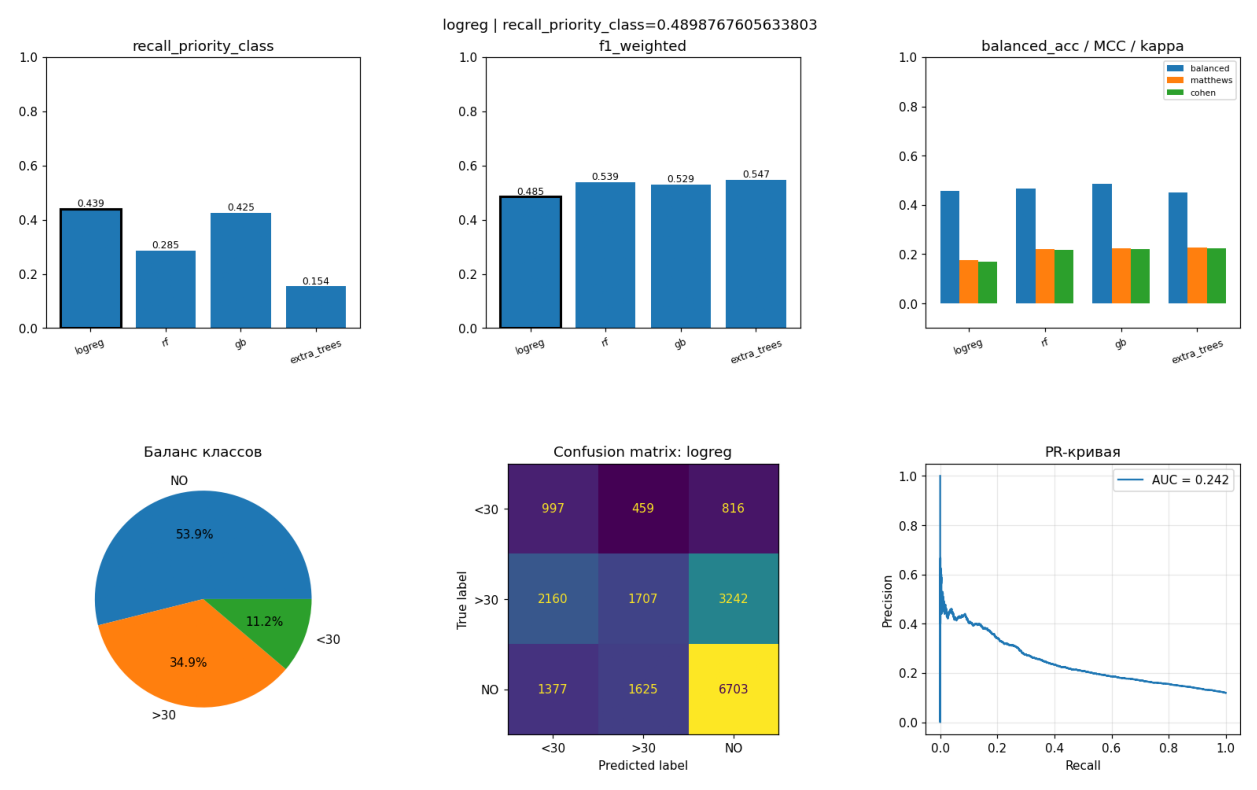

In [51]:
import matplotlib.image as mpimg

plots_path = f"{ARTIFACTS_DIR}/metrics.png"
if os.path.exists(plots_path):
    img = mpimg.imread(plots_path)
    fig, ax = plt.subplots(figsize=(16, 10))
    ax.imshow(img)
    ax.axis("off")
    plt.show()
else:
    print("metrics.png not found")

## Артефакты

После выполнения в artifacts/:

| Файл | Содержимое |
|---|---|
| `priority_records.csv` | Ранжированный список приоритетных наблюдений |
| `run_report.html` | Отчёт за сессию |
| `best_metrics.json` | Лучший результат (долговременная память) |
| `run_log.json` | Лог всех запусков |
| `architecture.json` | Описание пайплайна |
| `{logreg,rf,gb}.pkl` | Обученные модели |
| `metrics.png` | Графики сравнения |